In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy.stats import skew
from scipy.stats import zscore

In [2]:
df = pd.read_csv("train.csv")
pd.set_option("display.max_columns", None)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,5,1999,2000,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0,Unf,0,953,953,GasA,Ex,Y,SBrkr,953,694,0,1647,0,0,2,1,3,1,TA,7,Typ,1,TA,Attchd,1999.0,RFn,2,460,TA,TA,Y,0,40,0,0,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,Norm,1Fam,1Story,6,6,1978,1988,Gable,CompShg,Plywood,Plywood,Stone,119.0,TA,TA,CBlock,Gd,TA,No,ALQ,790,Rec,163,589,1542,GasA,TA,Y,SBrkr,2073,0,0,2073,1,0,2,0,3,1,TA,7,Min1,2,TA,Attchd,1978.0,Unf,2,500,TA,TA,Y,349,0,0,0,0,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,9,1941,2006,Gable,CompShg,CemntBd,CmentBd,NaN,0.0,Ex,Gd,Stone,TA,Gd,No,GLQ,275,Unf,0,877,1152,GasA,Ex,Y,SBrkr,1188,1152,0,2340,0,0,2,0,4,1,Gd,9,Typ,2,Gd,Attchd,1941.0,RFn,1,252,TA,TA,Y,0,60,0,0,0,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,6,1950,1996,Hip,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,TA,TA,Mn,GLQ,49,Rec,1029,0,1078,GasA,Gd,

## 1.SalePrice column

In [3]:
df["SalePrice"].isna().sum()

0

Analyze if there are any null values, no null values in SalePrice

In [4]:
df["SalePrice"].agg(['min','mean', 'median','max','std']).round(2)

min        34900.0
mean      180921.2
median    163000.0
max       755000.0
std        79442.5
Name: SalePrice, dtype: float64

Analyzing the descriptive statistics you can see there might be some problems on the skewness because the minimum value has a huge difference from the maximum value. Also the mean is significantly higher than the median which meanns the skewness might be affecting this value

In [5]:
df["SalePrice"].skew()

1.8828757597682129

The data is right skewed, above one to be adressed.

<Axes: xlabel='SalePrice', ylabel='Density'>

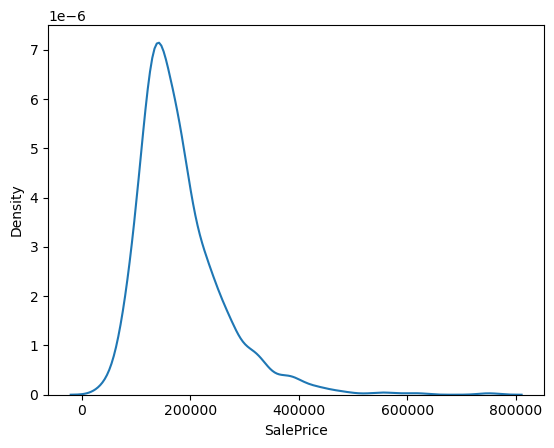

In [6]:
sns.kdeplot(x = 'SalePrice', data = df)

Data is right skewed and you can see a long tail to the right with a number of outliers. 

<Axes: xlabel='SalePrice'>

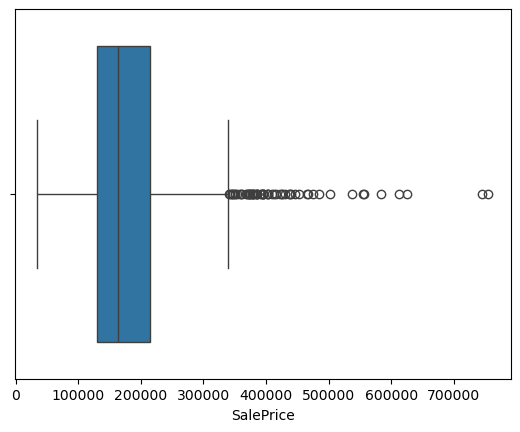

In [7]:
sns.boxplot(data=df,x="SalePrice")

The box plot allows for a more specific view of the number of outliers, we can see that most are grouped in a specific range but two are way out of the range of the box plot.

<Axes: xlabel='SalePrice', ylabel='Density'>

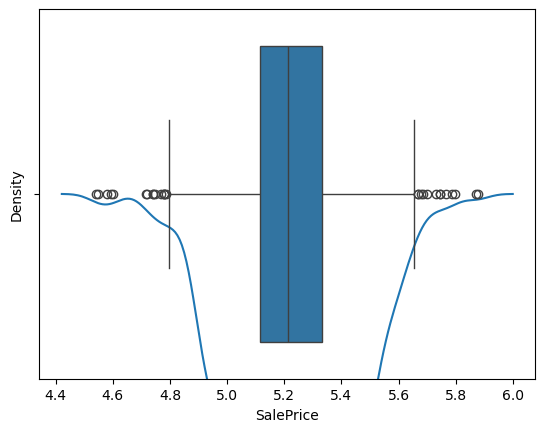

In [8]:
df["SalePrice"] = np.log10(df["SalePrice"])
sns.kdeplot(data=df,x="SalePrice")
display()
sns.boxplot(data=df,x="SalePrice")

Since there the outliers are equally spread out through the graph, I will first use a non-linear transformation to adjust the graph.

In [9]:
df["SalePrice"].skew()

0.12133506220521131

Check for the skew, almost eliminated and brought close to zero with log10 transformation.

In [10]:
col = "SalePrice"
mean = df[col].mean()
std = df[col].std()

lower = mean-3*std
upper = mean+3*std
outliers = df[(df[col]<lower)|(df[col]>upper)]
outliers[col].head()

30     4.602060
440    5.744293
495    4.542825
533    4.594393
691    5.877947
Name: SalePrice, dtype: float64

I'll use the 3 standard deviation method, because I believe there should be variety of sale prices and there shouldn't be a conservative amount for the number of sale prices we can hold. 

In [11]:
df[col] = df[col].clip(lower, upper)
print("\nWINSORIZING results:")
print("Outliers capped to the cutoff values of ", str(lower), "and ", str(upper))
print(col)
print(df[col].describe())


WINSORIZING results:
Outliers capped to the cutoff values of  4.701539729960322 and  5.742418182990933
SalePrice
count    1460.000000
mean        5.222151
std         0.171091
min         4.701540
25%         5.113860
50%         5.212188
75%         5.330414
max         5.742418
Name: SalePrice, dtype: float64


Using the winsorizing method we allow the most number of outliers to remain to have more variety in the data cleaned.

<Axes: xlabel='SalePrice'>

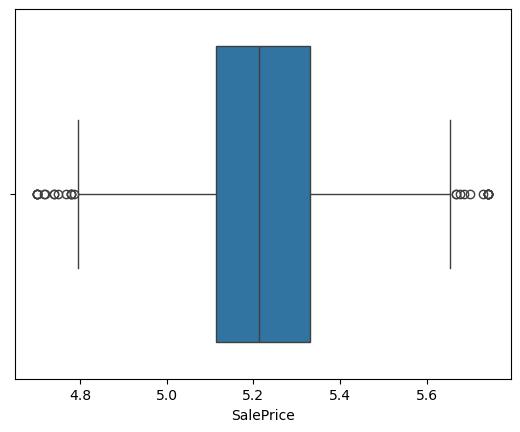

In [12]:
sns.boxplot(x="SalePrice",data=df)

In [13]:
df["SalePrice"] = zscore(df.SalePrice)

<Axes: xlabel='SalePrice'>

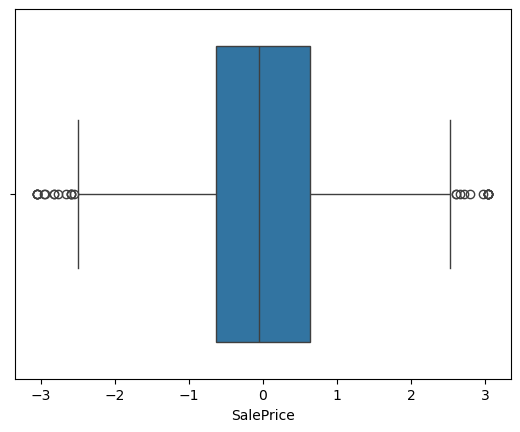

In [14]:
sns.boxplot(data=df,x="SalePrice")

0.16190451689092672


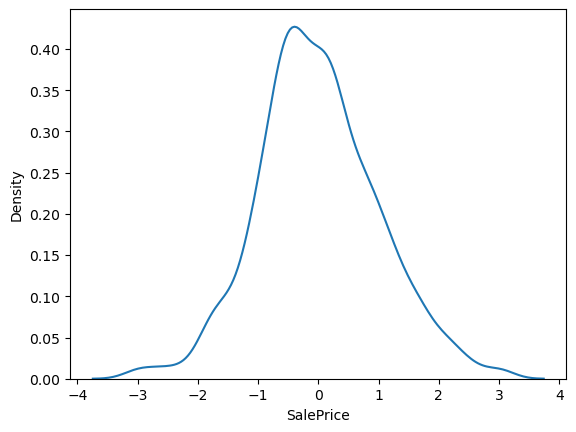

In [15]:
sns.kdeplot(data=df,x="SalePrice")
print(df["SalePrice"].skew())

Analyze and evaluate the transformation, less amounts of outliers, plus a more aligned graph with no skew.

In [16]:
df.loc[523, 'SalePrice'] = df[df['OverallQual'] == 10]['SalePrice'].mean()
df.loc[1298, 'SalePrice'] = df[df['OverallQual'] == 10]['SalePrice'].mean()
df.loc[632, 'SalePrice'] = df[df['Neighborhood'] == 'NWAmes']['SalePrice'].mean()

Outliers that were affecting the error and got rid of to increase the R squared.

In [17]:
df_model = pd.DataFrame(df['SalePrice'])

Create a separate dataframe for only cleaned variables for modelling

## 2.MSSubClass column: Exploration Process

In [18]:
display(df['MSSubClass'].isna().sum())

0

Check first if there are any null values, no null values.

<Axes: xlabel='MSSubClass', ylabel='count'>

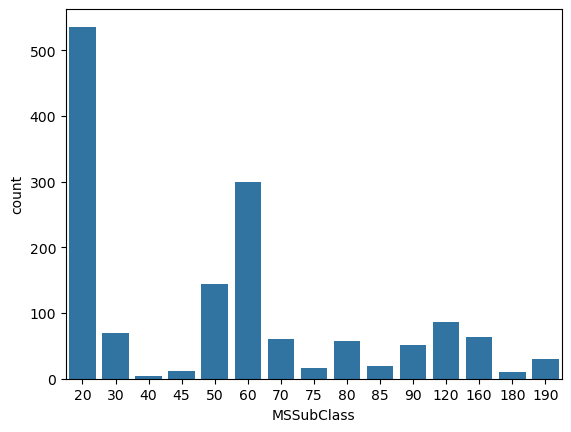

In [19]:
sns.countplot(x="MSSubClass",data=df)

You can see the most under-represented category is '40'.

In [20]:
df["MSSubClass"] = df["MSSubClass"].astype("string")
df.MSSubClass.value_counts(dropna=False)

MSSubClass
20     536
60     299
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: Int64

Change the data type to a string as it is a category class. See the unique values to analyze under-represented categories.

In [21]:
df.groupby("MSSubClass")["SalePrice"].mean()

MSSubClass
120    0.373544
160   -0.551669
180   -1.327261
190   -0.735352
20     0.078146
30    -1.486331
40    -0.391107
45    -1.131019
50    -0.528025
60     0.808835
70    -0.143681
75     0.102417
80    -0.006658
85    -0.326498
90    -0.618376
Name: SalePrice, dtype: float64

See the closest value of SalePrice mean now cleaned to '40' which in this case is '85'.

In [22]:
df.loc[df['MSSubClass']=='40','MSSubClass'] = '85'

Assign the under-represented category.

In [23]:
df.MSSubClass.value_counts(dropna=False)

MSSubClass
20     536
60     299
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      24
75      16
45      12
180     10
Name: count, dtype: Int64

Check the change.

<Axes: xlabel='MSSubClass', ylabel='SalePrice'>

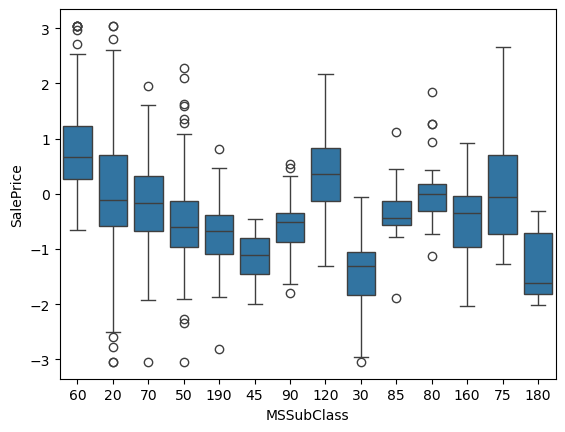

In [24]:
sns.boxplot(x="MSSubClass",y="SalePrice",data=df)

Through Bivariate exploration we can see there is a strong correlation between the type of 'MSSubcClass' and the 'SalePrice' at which the category will fall into with the highest being '60' and the lowest one '30'.

In [25]:
categorical_col = "MSSubClass"
dummies = pd.get_dummies( df[categorical_col],  prefix=categorical_col,dtype="int")
display(dummies.head())
df = pd.concat([df, dummies], axis=1)
df_model = pd.concat([df_model,dummies],axis=1)

,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90
0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0,1,0,0,0,0,0


One-hot encode the cleaned column to allow for machine learning exploration. Add cleaned varaibles to separate dataframe for only cleaned columns.

## 3.LotArea column: Exploration Process

In [26]:
df.LotArea.isnull().sum()

0

No null values to clean.

In [27]:
df["LotArea"].agg(['min','mean', 'median','max','std']).round(2)

min         1300.00
mean       10516.83
median      9478.50
max       215245.00
std         9981.26
Name: LotArea, dtype: float64

There is a very large difference between the minimum value and maximum value, understandable given Lot Area can vary a lot. There is a difference between mean and median, outliers may be affecting skew.

In [28]:
df["LotArea"].skew()

12.207687851233496

Right skew exists.

<Axes: xlabel='LotArea', ylabel='Density'>

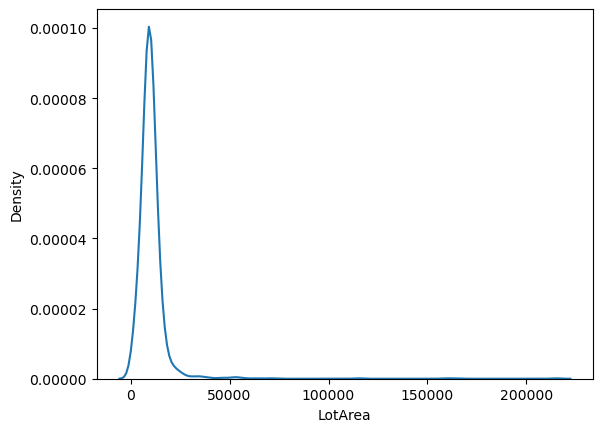

In [29]:
sns.kdeplot(x="LotArea",data=df)

<Axes: xlabel='LotArea'>

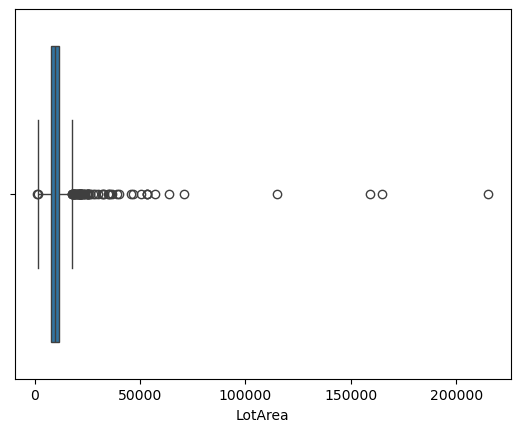

In [30]:
sns.boxplot(x="LotArea",data=df)

As you can see you have some outstanding outliers and the graph is heavily skewed to the right. Will transform first to have same number of outliers to both sides of the boxplot.

<Axes: xlabel='LotArea', ylabel='Density'>

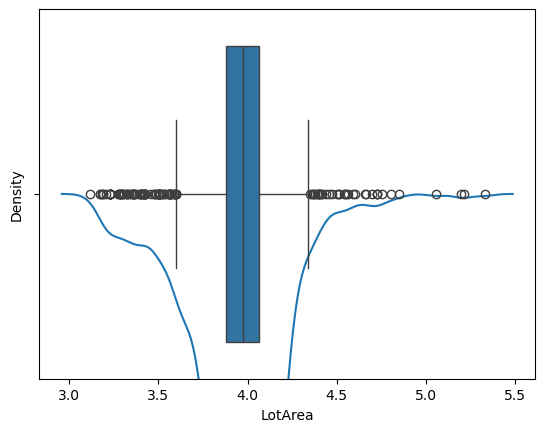

In [31]:
df["LotArea"] = np.log10(df["LotArea"])
sns.kdeplot(data=df,x="LotArea")
display()
sns.boxplot(data=df,x="LotArea")

Apply a transformation first to align the graph and eliminate skewness since the outliers are distributed all along the skew.

In [32]:
df["LotArea"] = df["LotArea"].copy()
col = "LotArea"
mean = df[col].mean()
std = df[col].std()

lower = mean-3*std
upper = mean+3*std
outliers = df[(df[col]<lower)|(df[col]>upper)]
outliers[col].head()

53     4.701318
75     3.203033
225    3.225309
227    3.271609
232    3.225309
Name: LotArea, dtype: float64

Since we want to maintain as much variety of data as possible we are using the 3 standard deviation to identify outliers, since Lot Area can be heavily varied.

In [33]:
df[col] = df[col].clip(lower, upper)
print("\nWINSORIZING results:")
print("Outliers capped to the cutoff values of ", str(lower), "and ", str(upper))
print(col)
print(df[col].describe())


WINSORIZING results:
Outliers capped to the cutoff values of  3.2826122507550495 and  4.6309612951057435
LotArea
count    1460.000000
mean        3.955506
std         0.212516
min         3.282612
25%         3.878148
50%         3.976740
75%         4.064514
max         4.630961
Name: LotArea, dtype: float64


Winsorize the results, to keep as many outliers as possible and allow for variability.

In [34]:
df["LotArea"].skew()

-0.5819017732770337

Appropiate skewness under -1.

In [35]:
df["LotArea"] = zscore(df.LotArea)

Standardize the cleaned column.

<Axes: xlabel='LotArea', ylabel='SalePrice'>

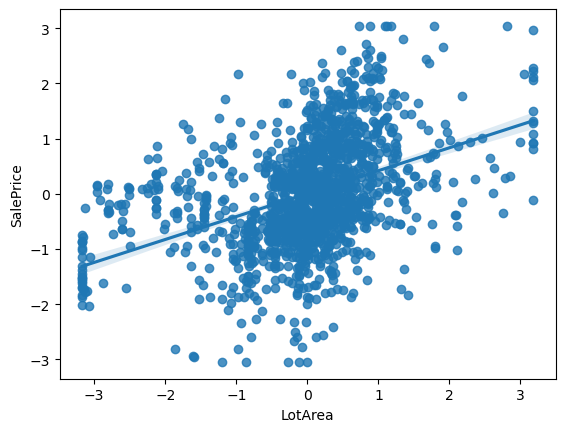

In [36]:
sns.regplot(x='LotArea',y="SalePrice",data=df)

In [37]:
df["LotArea"].corr(df["SalePrice"])

0.41433583759063813

In [38]:
df_model = pd.concat([df_model,df['LotArea']],axis=1)

After doing a bivariate exploration with Sale Price you can see it follows an upward trend, as Lot Area increases the Sale Price does to. However the index of only 0.25 tells that there is a relationship but not super strong.

## 4.LotFrontage column: Exploration Process

In [39]:
df.LotFrontage.isna().sum()

259

Large number of na values, I will clean this using linear regression

In [40]:
## HELP

In [41]:
df["LotFrontage"].corr(df["LotArea"])

0.6545691654564655

First I identify a strong correlation with already cleaned column of LotArea.

In [42]:
train_data = df[df['LotFrontage'].notnull()]   # Complete cases
missing_data = df[df['LotFrontage'].isnull()]  # Missing cases

reg_results = pg.linear_regression(
    X=train_data[['LotArea']],   # Independent variable
    y=train_data['LotFrontage']      # Dependent variable
)

print("REGRESSION RESULTS:")
print(reg_results)

# Extract coefficients
intercept = reg_results.loc[0, 'coef']   # Intercept
slope = reg_results.loc[1, 'coef'] 
print("The intercept of the model is", str(intercept), "and the slope is", str(slope))

REGRESSION RESULTS:
       names       coef        se           T           pval        r2  \
0  Intercept  70.977792  0.530891  133.695600   0.000000e+00  0.428461   
1    LotArea  16.336952  0.544915   29.980724  7.854117e-148  0.428461   

     adj_r2      CI2.5     CI97.5  
0  0.427984  69.936214  72.019371  
1  0.427984  15.267859  17.406046  
The intercept of the model is 70.97779230490055 and the slope is 16.336952182139694


The intercept represents the unit increase effect on LotFrontage, which is approximately 16 units. R^2 shows that approximately 43% of the prediction is explained by LotArea to LotFrontage.

In [43]:
predicted_values = intercept + slope * missing_data['LotArea']

    # Fill missing values
df.loc[df['LotFrontage'].isnull(), 'LotFrontage'] = predicted_values

Create the predicated values and assign them to the NA's

In [44]:
df["LotFrontage"].isna().sum()

0

Check that NA's have been replaced

In [45]:
df["LotFrontage"].agg(['min','mean', 'median','max','std']).round(2)

min        20.21
mean       70.98
median     70.00
max       313.00
std        23.33
Name: LotFrontage, dtype: float64

Large difference between minimum and maximum values, indicating possible outliers, mean and median almost the same signifying that the skew is not altering the mean.

In [46]:
df["LotFrontage"].skew()

1.9416461360513844

There is a right skew.

<Axes: xlabel='LotFrontage', ylabel='Density'>

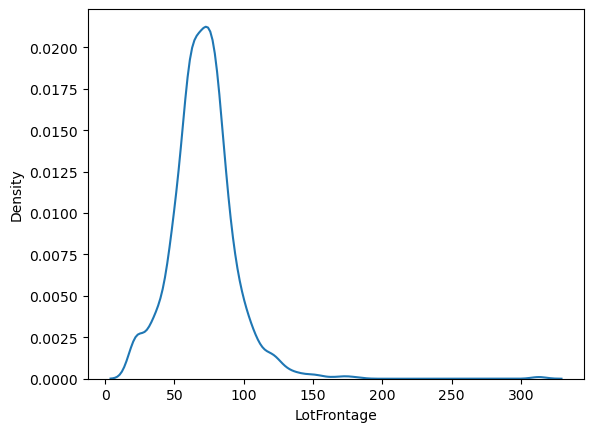

In [47]:
sns.kdeplot(x = 'LotFrontage', data = df)

<Axes: xlabel='LotFrontage'>

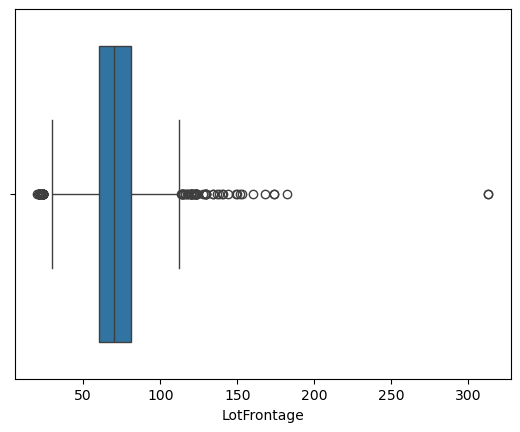

In [48]:
sns.boxplot(x = 'LotFrontage', data = df)

From both shapes you can see that the outliers, are mostly grouped except for a major one outside the reach of the boxplot and the grouped outliers. I will transform first to have the same number of outliers in both ends of the boxplot.

<Axes: xlabel='LotFrontage', ylabel='Density'>

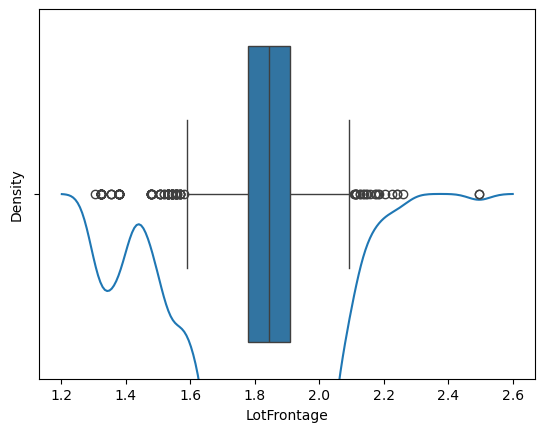

In [49]:
df["LotFrontage"] = np.log10(df["LotFrontage"])
sns.kdeplot(data=df,x="LotFrontage")
display()
sns.boxplot(data=df,x="LotFrontage")

In [50]:
df["LotFrontage"].skew()

-0.8963699084454076

Skew is much better under -1.

In [51]:
col = "LotFrontage"
mean = df[col].mean()
std = df[col].std()

lower = mean-3*std
upper = mean+3*std
outliers = df[(df[col]<lower)|(df[col]>upper)]
outliers[col].head()

56     1.380211
75     1.322219
145    1.380211
180    1.353091
193    1.380211
Name: LotFrontage, dtype: float64

Because of this, I still want to maintain the majority of variety of Lot Frontage values which is why I will use the 3 standard deviation method. 

In [52]:
df[col] = df[col].clip(lower, upper)
print("\nWINSORIZING results:")
print("Outliers capped to the cutoff values of ", str(lower), "and ", str(upper))
print(col)
print(df[col].describe())


WINSORIZING results:
Outliers capped to the cutoff values of  1.3811813082156505 and  2.274026151812491
LotFrontage
count    1460.000000
mean        1.828351
std         0.144241
min         1.381181
25%         1.778151
50%         1.845098
75%         1.908485
max         2.274026
Name: LotFrontage, dtype: float64


I will use the winsorize before transforming to try to get rid of the serious outlier while maintaining the most amount of values.

In [53]:
df["LotFrontage"] = zscore(df.LotFrontage)

Then you standardize the values in the column

<Axes: xlabel='LotFrontage', ylabel='SalePrice'>

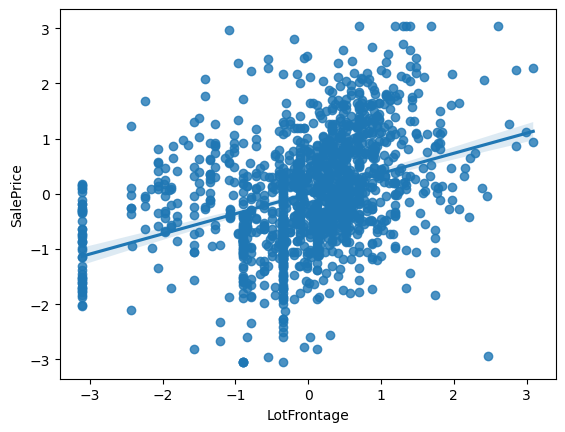

In [54]:
sns.regplot(x="LotFrontage",y="SalePrice",data=df)

In [55]:
df["LotFrontage"].corr(df["SalePrice"])
#regplot & correlation for bivariate for numerical

0.3642802803353093

Bivariate exploration with SalePrice, we can see a relationship between the price and the size of the Lot Frontage with a best fit line showing upward trend as the Lot Frontage increases price increases. However, the correlation index is 0.36 which is not too high, indicating a relationship exists but it is not too strong. 

In [56]:
df_model = pd.concat([df_model,df['LotFrontage']],axis=1)

## 5.LotConfig column: Exploration Process

In [57]:
display(df["LotConfig"].isna().sum())

0

Check for null values, no null values to be replaced.

<Axes: xlabel='LotConfig', ylabel='count'>

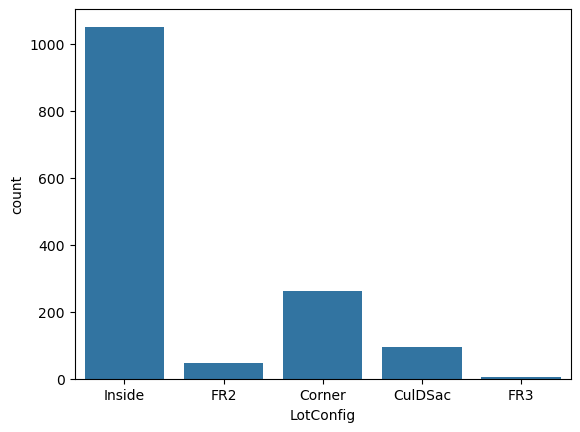

In [58]:
sns.countplot(x="LotConfig",data=df)

There is very low representation of "FR3" but high of "Inside".

In [59]:
df.LotConfig.value_counts(dropna=False)

LotConfig
Inside     1052
Corner      263
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64

See unique values, to check for under-represented 'FR3'.

In [60]:
df["LotConfig"] = df["LotConfig"].astype("string").str.strip().str.lower()

Change the value type to a string because it is a categorical value.

In [61]:
df.groupby("LotConfig")["SalePrice"].mean()

LotConfig
corner     0.010786
culdsac    0.568930
fr2        0.026141
fr3        0.434815
inside    -0.050313
Name: SalePrice, dtype: float64

Analyze the mean of the SalePrice to check which configuration works as the best replacement for under-represented values.

In [62]:
df.loc[df['LotConfig']=='fr3','LotConfig'] = 'corner'

Assign to the category to avoid under-representation.

In [63]:
df.LotConfig.value_counts(dropna=False)

LotConfig
inside     1052
corner      267
culdsac      94
fr2          47
Name: count, dtype: Int64

Check to see if the value was replaced.

<Axes: xlabel='LotConfig', ylabel='SalePrice'>

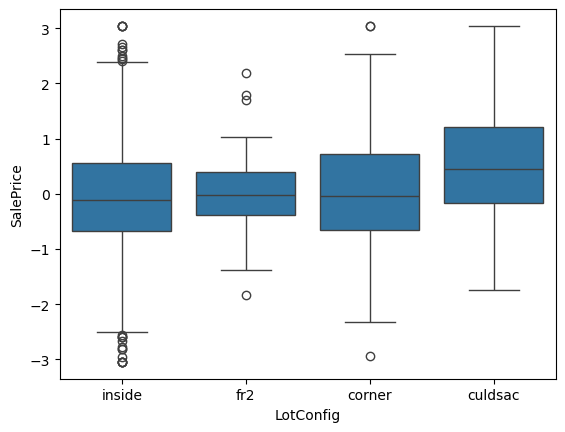

In [64]:
sns.boxplot(x="LotConfig",y="SalePrice",data=df)

Analyze through bivariate exploration the relationship between Lot configuration and the sale price, there is a relationship, you can see that there a equal sales distribution for most of the category of houses. 


In [65]:
dummies = pd.get_dummies(df["LotConfig"],prefix="LotConfig",dtype="int")
df = pd.concat([df, dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,-0.444494,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0
4,5,60,RL,0.665283,0.934904,Pave,NaN,IR1,Lvl,AllPub,fr2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,1.027813,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,-0.249388,-0.268049,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,5,1999,2000,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0,Unf,0,953,953,GasA,Ex,Y,SBrkr,953,694,0,1647,0,0,2,1,3,1,TA,7,Typ,1,TA,Attchd,1999.0,RFn,2,460,TA,TA,Y,0,40,0,0,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal,0.122125,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1
1456,1457,20,RL,0.700928,0.773125,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,NWAmes,Norm,Norm,1Fam,1Story,6,6,1978,1988,Gable,CompShg,Plywood,Plywood,Stone,119.0,TA,TA,CBlock,Gd,TA,No,ALQ,790,Rec,163,589,1542,GasA,TA,Y,SBrkr,2073,0,0,2073,1,0,2,0,3,1,TA,

One-hot encode the column for machine learning exploration and add it to the dataframe.

In [66]:
df_model = pd.concat([df_model,dummies],axis=1)

## 6. LandSlope column: Exploration Process

In [67]:
display(df["LandSlope"].isna().sum())
print(df["LandSlope"].dtype)

0

object


Check for potential null values to be cleaned, zero. Change the data type if applicable, variable type is appropiate.

<Axes: xlabel='LandSlope', ylabel='count'>

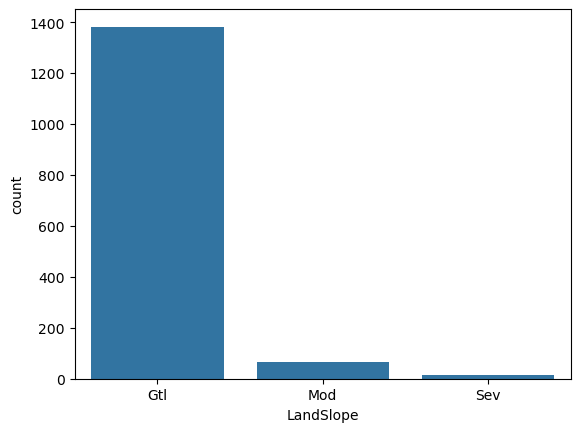

In [68]:
sns.countplot(x="LandSlope",data=df)

Low representation of 'Sev' while high representation of 'Gtl'.

In [69]:
df.LandSlope.value_counts(dropna=False)

LandSlope
Gtl    1382
Mod      65
Sev      13
Name: count, dtype: int64

Analyze the unique values to check for under-represented values, only 3 unique vairables in this column.

<Axes: xlabel='LandSlope', ylabel='SalePrice'>

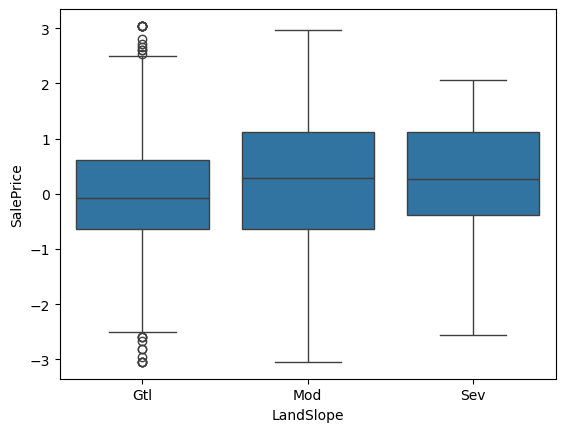

In [70]:
sns.boxplot(x="LandSlope",y="SalePrice",data=df)

Analyze the LandSlope column relationship with SalePrice, greatest variation exists between Gtl and SalePrice.

In [71]:
dummies = pd.get_dummies(df["LandSlope"],prefix="LandSlope",dtype="int")
df = pd.concat([df, dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,-0.444494,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0
4,5,60,RL,0.665283,0.934904,Pave,NaN,IR1,Lvl,AllPub,fr2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,1.027813,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,-0.249388,-0.268049,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,5,1999,2000,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0,Unf,0,953,953,GasA,Ex,Y,SBrkr,953,694,0,1647,0,0,2,1,3,1,TA,7,Typ,1,TA,Attchd,1999.0,RFn,2,460,TA,TA,Y,0,40,0,0,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal,0.122125,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0
1456,1457,20,RL,0.700928,0.773125,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,NWAmes,Norm,Norm,1Fam,1Story,6,6,1978,1988,Gable,CompShg,Plywood,Plywood,Stone,119.0,TA

One-hot encode the variable for machine learning exploration, and attach the hot encoded columns to the dataframe.

In [72]:
df_model = pd.concat([df_model,dummies],axis=1)

## 7. Neighborhood column: Exploration Process

In [73]:
display(df["Neighborhood"].isna().sum())
print(df["Neighborhood"].dtype)

0

object


First I checked the null values, no null values and saw the data type which is appropiate for the column.

In [74]:
df.Neighborhood.value_counts(dropna=False)

Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
StoneBr     25
SWISU       25
MeadowV     17
Blmngtn     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

Check the unique values of the column for under-represented values. In this case re-assign "NPkVill" and "Blueste" due to under-representation.

C:\Users\camfl\AppData\Local\Temp\ipykernel_31572\1175047734.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  graph.set_xticklabels(graph.get_xticklabels(),rotation=45,ha='right')


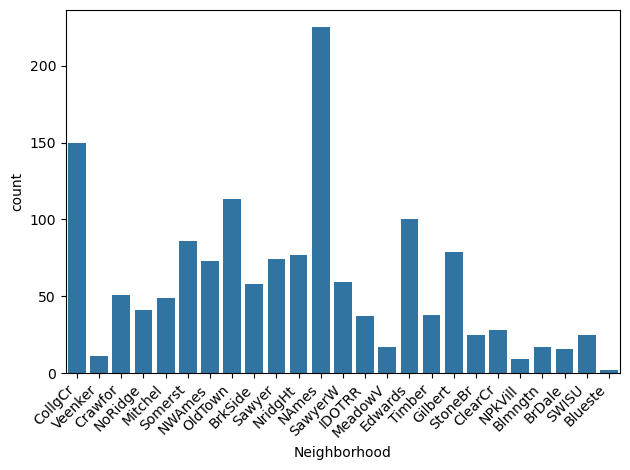

In [75]:
graph = sns.countplot(x="Neighborhood",data=df)
graph.set_xticklabels(graph.get_xticklabels(),rotation=45,ha='right')
plt.tight_layout()

Low representation of Blueste, NPkVil, and BrDale.

In [76]:
df.groupby("Neighborhood")["SalePrice"].mean()

Neighborhood
Blmngtn    0.368113
Blueste   -0.502545
BrDale    -1.210164
BrkSide   -0.864530
ClearCr    0.547091
CollgCr    0.353451
Crawfor    0.462684
Edwards   -0.749606
Gilbert    0.333548
IDOTRR    -1.401488
MeadowV   -1.396398
Mitchel   -0.229800
NAmes     -0.397144
NPkVill   -0.401124
NWAmes     0.297750
NoRidge    1.609008
NridgHt    1.505515
OldTown   -0.807680
SWISU     -0.472331
Sawyer    -0.540808
SawyerW    0.168207
Somerst    0.690802
StoneBr    1.423895
Timber     0.860830
Veenker    0.811874
Name: SalePrice, dtype: float64

After grouping by Neighborhood, mean SalePrice and the closest value is the most appropiate NAmes is the closest value for NPkVill and BrDale is the closest for Blueste. Given that the Neighborhood tends to dictate SalePrice for home this is the most appropiate value replacement.

In [77]:
df["Neighborhood"] = df["Neighborhood"].astype("string").str.strip().str.lower()

To avoid any formatting issues we strip the white space and lower case the neighborhood.

In [78]:
df.loc["npkvill"==df["Neighborhood"],"Neighborhood"] = "names"
df.loc["blueste"==df["Neighborhood"],"Neighborhood"] = "brdale"

Assign NPkVill and Blueste to NAmes and BrDale respectively for better analysis of these under-represented values.

In [79]:
df.Neighborhood.value_counts(dropna=False)

Neighborhood
names      234
collgcr    150
oldtown    113
edwards    100
somerst     86
gilbert     79
nridght     77
sawyer      74
nwames      73
sawyerw     59
brkside     58
crawfor     51
mitchel     49
noridge     41
timber      38
idotrr      37
clearcr     28
stonebr     25
swisu       25
brdale      18
meadowv     17
blmngtn     17
veenker     11
Name: count, dtype: Int64

Check for replacement.

C:\Users\camfl\AppData\Local\Temp\ipykernel_31572\3457197483.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  graph.set_xticklabels(graph.get_xticklabels(),rotation=45,ha='right')


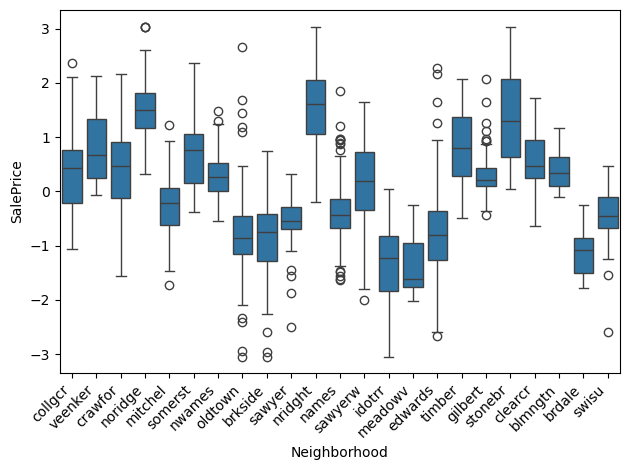

In [80]:
graph = sns.boxplot(x="Neighborhood",y="SalePrice",data=df)
graph.set_xticklabels(graph.get_xticklabels(),rotation=45,ha='right')
plt.tight_layout()

Bivariate exploration between Neighborhood and SalePrice, you can see a lot of variation between the Neighborhood as well as variety and number of different SalePrice.

In [81]:
dummies = pd.get_dummies(df["Neighborhood"],prefix="Neighborhood",dtype="int")
df = pd.concat([df, dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,-0.444494,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,5,60,RL,0.665283,0.934904,Pave,NaN,IR1,Lvl,AllPub,fr2,Gtl,noridge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,1.027813,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,..

One-hot encode the newly cleaned column for machine learning exploration, and attach Neighborhood cleaned column to the data frame.

In [82]:
df_model = pd.concat([df_model,dummies],axis=1)

## 8. OverallQual column: Exploration Process

In [83]:
display(df['OverallQual'].isna().sum())
print(df['OverallQual'].dtype)

0

int64


Check for null values in the column, and the data type needs to be changed to a string because it falls under a ordinal value description.

<Axes: xlabel='OverallQual', ylabel='count'>

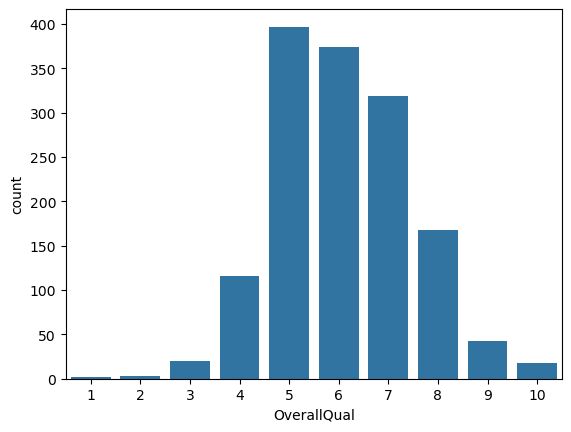

In [84]:
sns.countplot(x="OverallQual",data=df)

Very low representation of 1,2,3 and possibly 10.

In [85]:
df['OverallQual'] = df['OverallQual'].astype("string")
df['OverallQual'].value_counts(dropna=False)

OverallQual
5     397
6     374
7     319
8     168
4     116
9      43
3      20
10     18
2       3
1       2
Name: count, dtype: Int64

Check for under-represented values and turn to a string because this rating of quality is a ordinal value.

In [86]:
df.loc["1"==df["OverallQual"],"OverallQual"] = "3"
df.loc["2"==df["OverallQual"],"OverallQual"] = "3"
df["OverallQual"].value_counts(dropna=False)

OverallQual
5     397
6     374
7     319
8     168
4     116
9      43
3      25
10     18
Name: count, dtype: Int64

Since it is a ordinal value we replace it with the next closest level, for both '1' and '2' it would be '3'.

<Axes: xlabel='OverallQual', ylabel='SalePrice'>

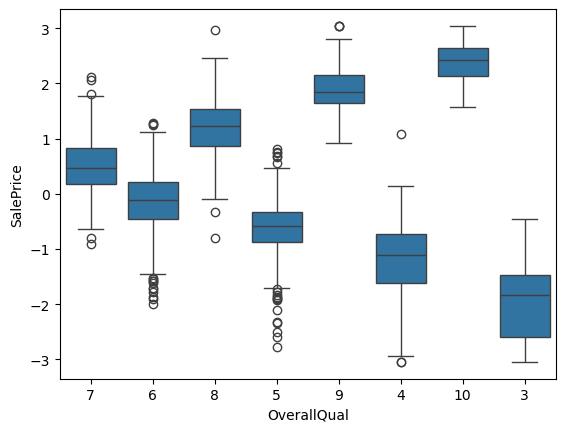

In [87]:
sns.boxplot(x="OverallQual",y="SalePrice",data=df)

Do a bivariate analysis of the OverallQual with the SalePrice column, there is a very clear relationship because as SalePrice increases the quality of the house is greater.

In [88]:
dummies = pd.get_dummies(df["OverallQual"],prefix="OverallQual",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,-0.444494,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,5,60,RL,0.665283,0.934904,Pave,NaN,IR1,Lvl,AllPub,fr2,Gtl,noridge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,1.027813,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,.

One-hot encode the cleaned "OverallQual" for machine learning exploration and attach it to the dataframe.

In [89]:
df_model = pd.concat([df_model,dummies],axis=1)

## 9. ExterQual column: Exploration Process

In [90]:
display(df['ExterQual'].isna().sum())
print(df["ExterQual"].dtype)

0

object


Check for the na's in the dataframe and later check for the data type of the column to change if necessary.

<Axes: xlabel='ExterQual', ylabel='count'>

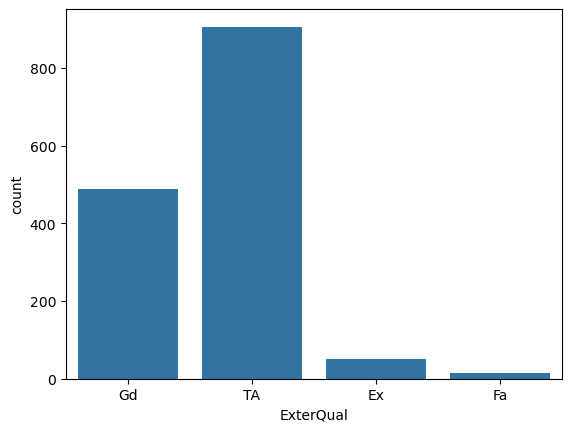

In [91]:
sns.countplot(x="ExterQual",data=df)

There seems to be under-represented values like Fa but given that the number of counts is really big.

In [92]:
df['ExterQual'].value_counts(dropna=False)

ExterQual
TA    906
Gd    488
Ex     52
Fa     14
Name: count, dtype: int64

Analyze the unique values for under-representation, which there are none.

<Axes: xlabel='ExterQual', ylabel='SalePrice'>

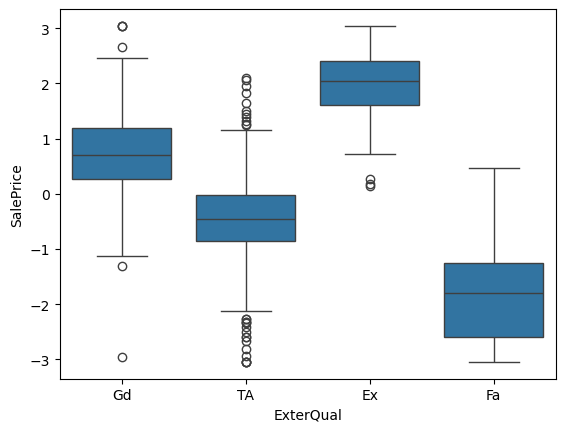

In [93]:
sns.boxplot(x="ExterQual",y="SalePrice",data=df)

See the relationship between 'ExterQual' and 'SalePrice' as it seems to be that the relationship as it has a lower rating the sale price descreases and the other way around.

In [94]:
dummies = pd.get_dummies(df["ExterQual"],prefix="ExterQual",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,-0.444494,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1
4,5,60,RL,0.665283,0.934904,Pave,NaN,IR1,Lvl,AllPub,fr2,Gtl,noridge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,1.027813,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0

One-hot encode the cleaned ExterQual and attach it to the dataframe for machine learning exploration.

In [95]:
df_model = pd.concat([df_model,dummies],axis=1)

## 10. Fireplaces exploration process

In [96]:
print(df["Fireplaces"].isna().sum())
print(df["Fireplaces"].dtype)

0
int64


Check for the data type, need to change it to a string due to unique values less than 5 and also no null values to be cleaned.

<Axes: xlabel='Fireplaces', ylabel='count'>

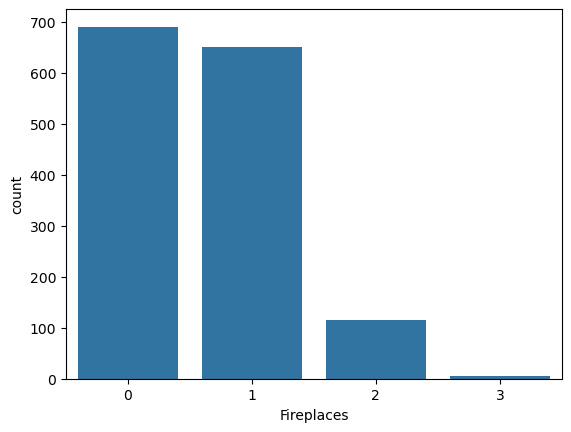

In [97]:
sns.countplot(x="Fireplaces",data=df)

There seems to be under-representation of '3'.

In [98]:
df["Fireplaces"] = df["Fireplaces"].astype("string")
df["Fireplaces"].value_counts(dropna=False)

Fireplaces
0    690
1    650
2    115
3      5
Name: count, dtype: Int64

Change the data type to string, then check for under-represented unique values, '3' needs to be assigned to another since it holds low number of counts.

In [99]:
df.loc["3"==df["Fireplaces"],"Fireplaces"] = "2"
df["Fireplaces"].value_counts(dropna=False)

Fireplaces
0    690
1    650
2    120
Name: count, dtype: Int64

Since the column has ordinal values, I am replacing '3' with '2' because it is the closest level. 

<Axes: xlabel='Fireplaces', ylabel='SalePrice'>

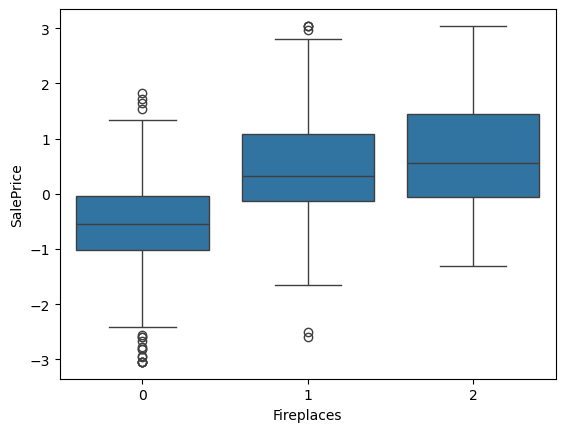

In [100]:
sns.boxplot(x="Fireplaces",y="SalePrice",data=df)

Analyze the relationship between the number of Fireplaces and the SalePrice, as you can see as the number of Fireplaces increases so does the SalePrice. Clear relationship.

In [101]:
dummies = pd.get_dummies(df["Fireplaces"],prefix="Fireplaces",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,-0.444494,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0
4,5,60,RL,0.665283,0.934904,Pave,NaN,IR1,Lvl,AllPub,fr2,Gtl,noridge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,1.027813,0,0,0,

Once you analyze the relationship, you hot-encode the cleaned values of Fireplaces for machine learning exploration and attach it to the dataframe.

In [102]:
df_model = pd.concat([df_model,dummies],axis=1)

## 11. FireplaceQu exploration process

In [103]:
print(df["FireplaceQu"].isna().sum())
print(df["FireplaceQu"].dtype)

690
object


Check for null values, there are 690 null values to be cleaned. Check the data type since it is categorical data type is fine.

In [104]:
df["FireplaceQu"] = df["FireplaceQu"].fillna("None")

Since the null values represent houses with no Fireplace we assign a new category 'None' that accounts for this houses.

In [105]:
df["FireplaceQu"].value_counts(dropna=False)

FireplaceQu
None    690
Gd      380
TA      313
Fa       33
Ex       24
Po       20
Name: count, dtype: int64

Check for the unique value counts to check for under-represented value in the column, none here are under-represented.

<Axes: xlabel='FireplaceQu', ylabel='SalePrice'>

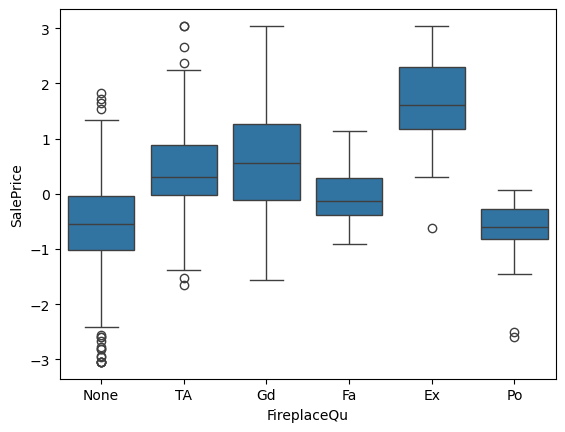

In [106]:
df["FireplaceQu"] = df["FireplaceQu"].astype("string")
sns.boxplot(x="FireplaceQu",y="SalePrice",data=df)

There seems to be a not too strong relationship, however poor and none categories do have a lower price.

In [107]:
dummies = pd.get_dummies(df["FireplaceQu"],prefix="FireplaceQu",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,-0.444494,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0
4,5,60,RL,0.665283,0.934904,Pave,NaN,IR1,Lvl,AllPub,fr2,Gtl,noridge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SB

One-hot encode the variable for machine learning with cleaned FireplaceQu cleaned and add the encoded variables to the dataframe.

In [108]:
df_model = pd.concat([df_model,dummies],axis=1)

## 12. BsmtFullBath exploration process

In [109]:
print(df["BsmtFullBath"].isna().sum())
print(df['BsmtFullBath'].dtype)

0
int64


First check for the null values in the column, no null values to be cleaned. Check the data type to change, since this accounts for less than 5 unique variables it is a string data type.

<Axes: xlabel='BsmtFullBath', ylabel='count'>

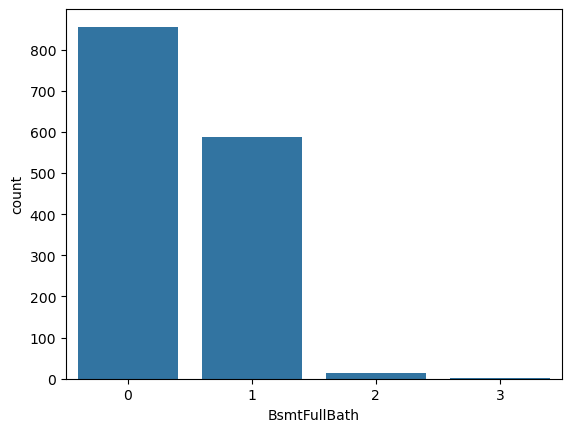

In [110]:
sns.countplot(x="BsmtFullBath",data=df)

There seems to be under-representation '3'.

In [111]:
df["BsmtFullBath"].value_counts(dropna=False)

BsmtFullBath
0    856
1    588
2     15
3      1
Name: count, dtype: int64

Check for under-represented category, '3' needs to be re-assigned due to its low representation.

In [112]:
df["BsmtFullBath"] = df["BsmtFullBath"].astype("string")
df.loc["3"==df["BsmtFullBath"],"BsmtFullBath"] = "2"

Change the data type to a string and re-assign '3', since it is a ordinal value to the closest level '2'.

<Axes: xlabel='BsmtFullBath', ylabel='SalePrice'>

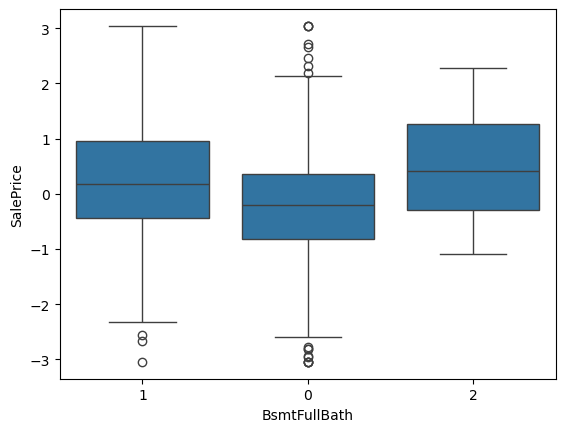

In [113]:
sns.boxplot(x="BsmtFullBath",y="SalePrice",data=df)

Bivariate exploration to analyze the relationship between the SalePrice and the Basement Full bath, there does not seem to be a strong relationship.

In [114]:
dummies = pd.get_dummies(df["BsmtFullBath"],prefix="BsmtFullBath",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,-0.444494,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,0
4,5,60,RL,0.665283,0.934904,Pave,NaN,IR1,Lvl,AllPub,fr2,Gtl,noridge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,B

One-hot encode the cleaned column and assign the hot encoded variables to the dataframe for machine learning exploration.

In [115]:
df_model = pd.concat([df_model,dummies],axis=1)

## 13. BsmtHalfBath

In [116]:
print(df["BsmtHalfBath"].isna().sum())
print(df["BsmtHalfBath"].dtype)

0
int64


Check for null values, there are no null values to be cleaned and change the data type to a string.

<Axes: xlabel='BsmtHalfBath', ylabel='count'>

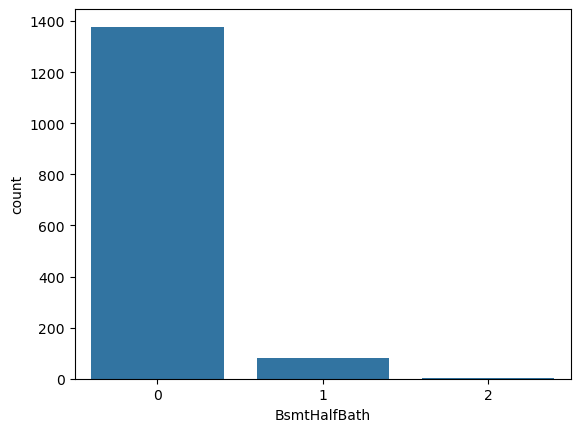

In [117]:
sns.countplot(x="BsmtHalfBath",data=df)

Serious under-representation of '2'.

In [118]:
df["BsmtHalfBath"].value_counts(dropna=True)

BsmtHalfBath
0    1378
1      80
2       2
Name: count, dtype: int64

Since the unique value counts are less than 5 you need to change it to a string type.

In [119]:
df["BsmtHalfBath"] = df["BsmtHalfBath"].astype("string")
df.loc["2"==df["BsmtHalfBath"],"BsmtHalfBath"] = "1"

Change the data type to a strong, and later since '2' only has 2 counts you need to assign it to the next closest level because this an ordinal value.

<Axes: xlabel='BsmtHalfBath', ylabel='SalePrice'>

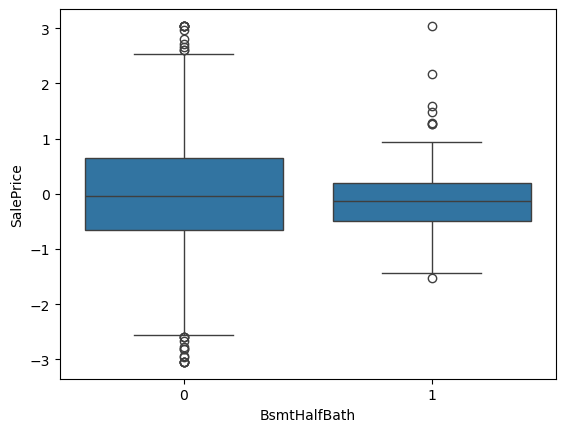

In [120]:
sns.boxplot(x="BsmtHalfBath",y="SalePrice",data=df)

Bivariate exploration shows that 'BsmtHalfBath' has a not too strong relationship with SalePrice, meaning that the number of half bath's in the basement does not influence price heavily.

In [121]:
dummies = pd.get_dummies(df["BsmtHalfBath"],prefix="BsmtHalfBath",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0,0,1
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,-0.444494,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0
4,5,60,RL,0.665283,0.934904,Pave,NaN,IR1,Lvl,AllPub,fr2,Gtl,noridge,Norm,Norm,1Fam,2Story

One-hot encode the column for machine learning exploration and attach it to the dataframe.

In [122]:
df_model = pd.concat([df_model,dummies],axis=1)

## 14. FullBath

In [123]:
print(df["FullBath"].isna().sum())
print(df["FullBath"].dtype)

0
int64


Check null values, zero values to be cleaned. And check the data type for changing.

In [124]:
df["FullBath"].value_counts(dropna=False)

FullBath
2    768
1    650
3     33
0      9
Name: count, dtype: int64

Since there are less than 5 unique variables data type needs to be changed to a string.

<Axes: xlabel='FullBath', ylabel='count'>

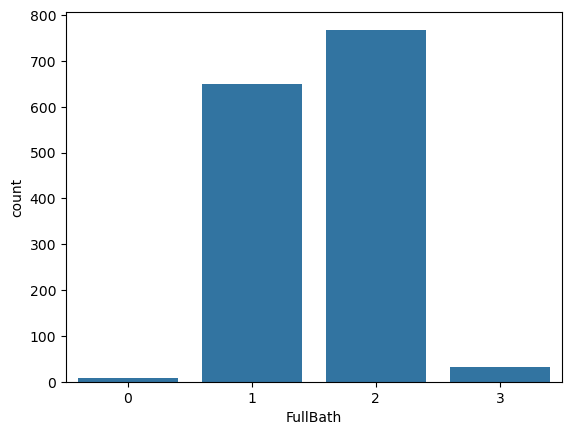

In [125]:
sns.countplot(x="FullBath",data=df)

'0' is under-represented in this column as you can see in the countplot.

In [126]:
df["FullBath"] = df["FullBath"].astype("string")
df.loc["0"==df["FullBath"],"FullBath"] = "1"

First change the data type to a string. Since these ordinal values under-represented '0' needs to go to the closest level '1'.

<Axes: xlabel='FullBath', ylabel='SalePrice'>

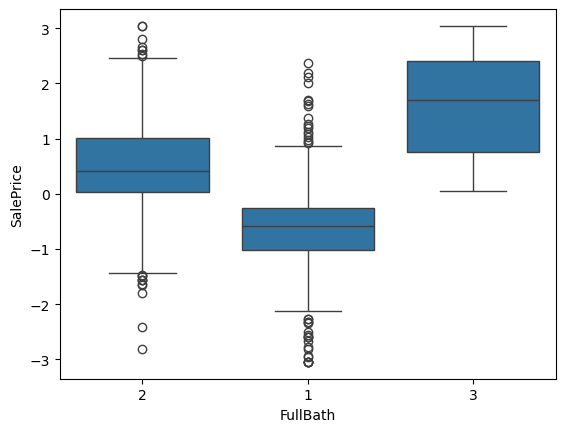

In [127]:
sns.boxplot(x="FullBath",y="SalePrice",data=df)

Bivariate exploration between FullBath and SalePrice shows that there exists a variation between a FullBath and the SalePrice, as there are more FullBath SalePrice increases.

In [128]:
dummies = pd.get_dummies(df["FullBath"],prefix="FullBath",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0,0,1,0
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,-0.444494,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,1,0,0
4,5,60,RL,0.665283,0.934904,Pave

Create dummy vairables for the cleaned column to facilitate machine learning exploration and add it to the dataframe.

In [129]:
df_model = pd.concat([df_model,dummies],axis=1)

## 15. HalfBath

In [130]:
print(df["HalfBath"].isna().sum())
print(df["HalfBath"].dtype)

0
int64


Check for null values. No null values. Change the data type from integer if needed.

<Axes: xlabel='HalfBath', ylabel='count'>

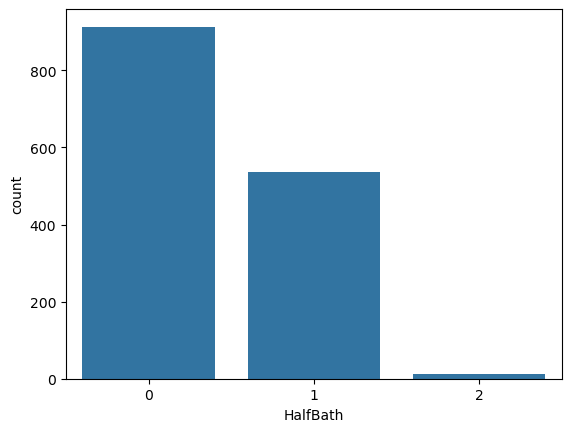

In [131]:
sns.countplot(x="HalfBath",data=df)

There seems to be an under-representation of '2'.

In [132]:
df["HalfBath"].value_counts(dropna=False)

HalfBath
0    913
1    535
2     12
Name: count, dtype: int64

See the unique values, since there are less than 5 unique variables need to change the data type to a string but there are no major under-represented values.

<Axes: xlabel='HalfBath', ylabel='SalePrice'>

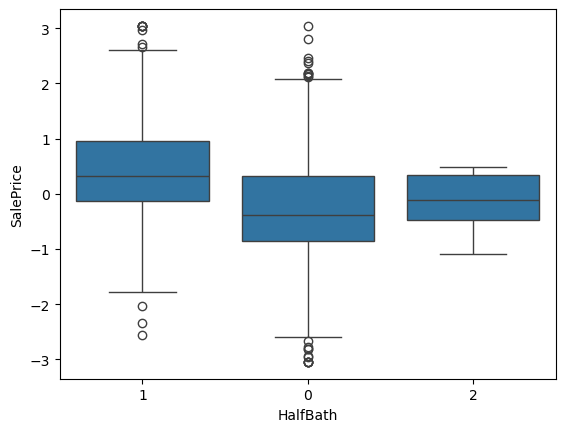

In [133]:
df["HalfBath"] = df["HalfBath"].astype("string")
sns.boxplot(x="HalfBath",y="SalePrice",data=df)

See the relationship, between the HalfBath and the SalePrice, SalePrice does seem to decrease as the number of HalfBath decreases but it is not a too strong relationship.

In [134]:
dummies = pd.get_dummies(df["HalfBath"],prefix="HalfBath",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3,HalfBath_0,HalfBath_1,HalfBath_2
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,1,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0,1,0,0
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0,0,1,0,0,1,0
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,-0.444494,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0

One-hot encode the column for machine learning exploration and then add it to the dataframe.

In [135]:
df_model = pd.concat([df_model,dummies],axis=1)

## 16. GarageType exploration process

In [136]:
df["GarageType"].isna().sum()

81

Start by analyzing the number of null values to be replaced. There are 81 null values that need cleaning.

In [137]:
df["GarageType"] = df["GarageType"].fillna("None")

Since the null values account for a type of property that does not have a garage, we assign it to a new category called 'None'.

<Axes: xlabel='GarageType', ylabel='count'>

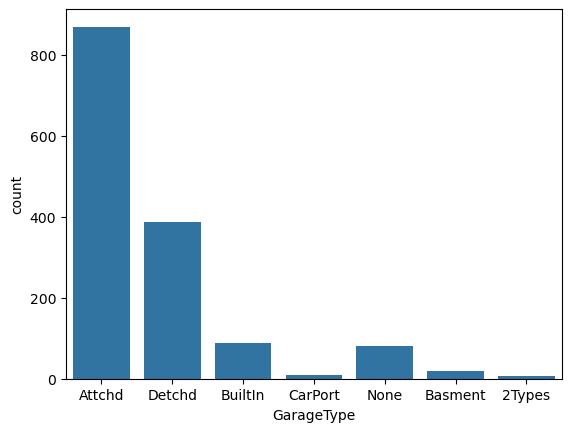

In [138]:
sns.countplot(x="GarageType",data=df)

Possible under-representation of "2Types".

In [139]:
df["GarageType"].value_counts(dropna=False)

GarageType
Attchd     870
Detchd     387
BuiltIn     88
None        81
Basment     19
CarPort      9
2Types       6
Name: count, dtype: int64

See the unique values and their counts to analyze the under-represented values.

In [140]:
df.groupby("GarageType")["SalePrice"].mean()

GarageType
2Types    -0.318143
Attchd     0.348834
Basment   -0.274257
BuiltIn    0.909934
CarPort   -1.108264
Detchd    -0.653343
None      -1.324275
Name: SalePrice, dtype: float64

Then grouby by the GarageType and get the mean of the SalePrice, and replace the under-represented values '2Types' and 'CarPort' with the closest mean.

In [141]:
df.loc["2Types"==df["GarageType"],"GarageType"] = "Basment"
df.loc["CarPort"==df["GarageType"],"GarageType"] = "Detchd"
df["GarageType"].value_counts(dropna=False)

GarageType
Attchd     870
Detchd     396
BuiltIn     88
None        81
Basment     25
Name: count, dtype: int64

Replace the under-represented values of '2Types' and 'CarPort' with the closest one which are 'Basment' and 'Detchd' respectively. 

<Axes: xlabel='GarageType', ylabel='SalePrice'>

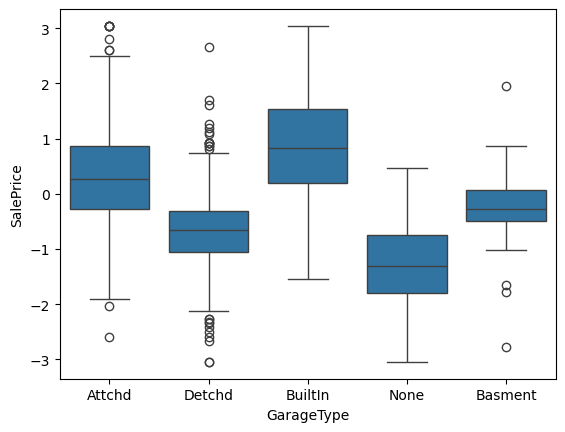

In [142]:
sns.boxplot(x="GarageType",y="SalePrice",data=df)

Bivariate exploration demonstrates that there exists a relationship between the GarageType and SalePrice you can see that indeed depending on the type of GarageType the SalePrice will increase and there is a strong enough relationship.

In [143]:
dummies = pd.get_dummies(df["GarageType"],prefix="GarageType",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3,HalfBath_0,HalfBath_1,HalfBath_2,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_Detchd,GarageType_None
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,1,0,1,0,0,0,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0,1,0,0,1,0,0,0,0
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0,0,1,0,0,1,0,1,0,0,0,0
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,-0.444494,0,0,0,0

One-hot encode the variables and attach it to the dataframe for machine learning exploration.

In [144]:
df_model = pd.concat([df_model,dummies],axis=1)

## 17. GarageFinish

In [145]:
df["GarageFinish"].isna().sum()

81

There are significant null valuest to be cleaned.

<Axes: xlabel='GarageFinish', ylabel='count'>

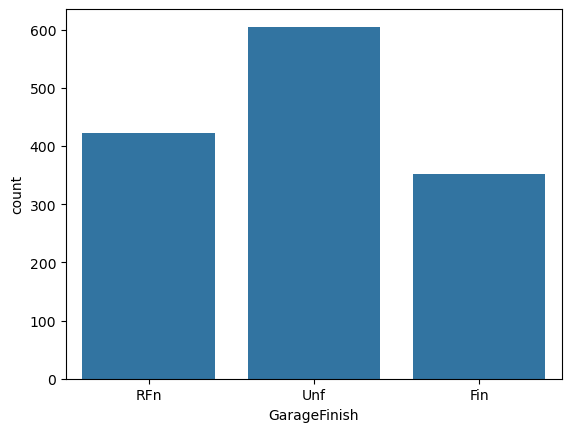

In [146]:
sns.countplot(x="GarageFinish",data=df)

No under-representation of the unique values.

In [147]:
df["GarageFinish"] = df["GarageFinish"].fillna("None")
df["GarageFinish"].value_counts(dropna=False)

GarageFinish
Unf     605
RFn     422
Fin     352
None     81
Name: count, dtype: int64

We assign all null values to a category named 'None', for houses that do not have a 'Garage'.

<Axes: xlabel='GarageFinish', ylabel='SalePrice'>

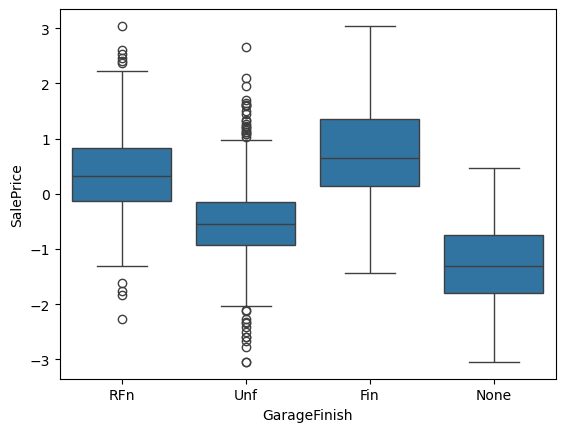

In [148]:
sns.boxplot(x="GarageFinish",y="SalePrice",data=df)

After doing a bivariate analysis we can see that the state of a finished 'Garage' will influence the SalePrice as the ones that do not have one have the lowest prices and the ones finished the highest.

In [149]:
dummies = pd.get_dummies(df["GarageFinish"],prefix="GarageFinish",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3,HalfBath_0,HalfBath_1,HalfBath_2,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Det

One-hot encode the variables for machine learning exploration after cleaning the "GarageFinish" column and add it to the data frame.

In [150]:
df_model = pd.concat([df_model,dummies],axis=1)

## 18. GarageCars

In [151]:
print(df["GarageCars"].isna().sum())
print(df["GarageCars"].dtype)

0
int64


Check if there are any null values to be cleaned. No null values to be cleaned. Check data type if to be changed, need to change to a string because there are only 5 unique variables and they represent a count.

<Axes: xlabel='GarageCars', ylabel='count'>

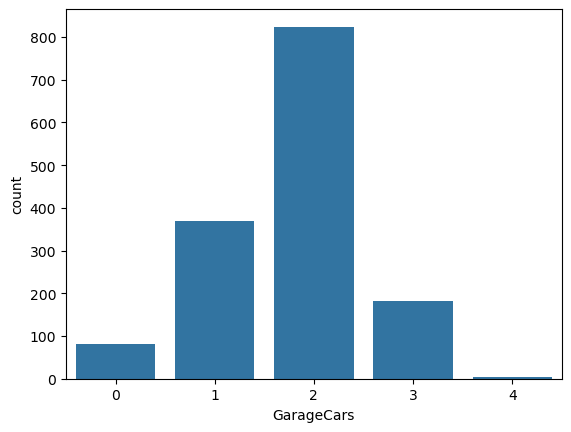

In [152]:
sns.countplot(x="GarageCars",data=df)

Possible under-representation of '4', possible replacement value is '3'.

In [153]:
df["GarageCars"].value_counts(dropna=False)

GarageCars
2    824
1    369
3    181
0     81
4      5
Name: count, dtype: int64

Then check for unique values to see if there are any under-represented values, I first saw that we need to re-assign four because it has low number of variables.

In [154]:
df["GarageCars"] = df["GarageCars"].astype("string")
df.loc["4"==df["GarageCars"],"GarageCars"] = "3"

After changing the data type to a string, we also re-assign the under-represented value.

<Axes: xlabel='GarageCars', ylabel='SalePrice'>

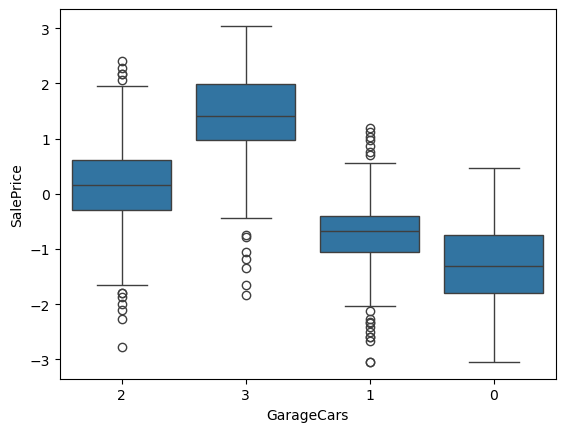

In [155]:
sns.boxplot(x="GarageCars",y="SalePrice",data=df)

Bivariate analysis with SalePrice to see a strong relationship between the number of cars the garage can hold and the sale price, as cars increase sale price also increases.

In [156]:
dummies = pd.get_dummies(df["GarageCars"],prefix="GarageCars",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3,HalfBath_0,HalfBath_1,HalfBath_2,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageCars_0,GarageCars_1,GarageCars_2,GarageCars_3
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,21

One-hot encode the vairables of "GarageCars" for machine learning exploration after cleaning and add them to the data frame.

In [157]:
df_model = pd.concat([df_model,dummies],axis=1)

## 19. GarageArea

In [158]:
df["GarageArea"].isna().sum()

0

Check for any null values, to be cleaned, none to be cleaned here.

In [159]:
df["GarageArea"].agg(['min','mean','median','max','std'])

min          0.000000
mean       472.980137
median     480.000000
max       1418.000000
std        213.804841
Name: GarageArea, dtype: float64

There is a variation between mean and median, possibly pointinting to some outliers.

In [160]:
df["GarageArea"].skew()

0.17998090674623907

There is a very light skew, which is less than one for it to be transformed.

<Axes: xlabel='GarageArea'>

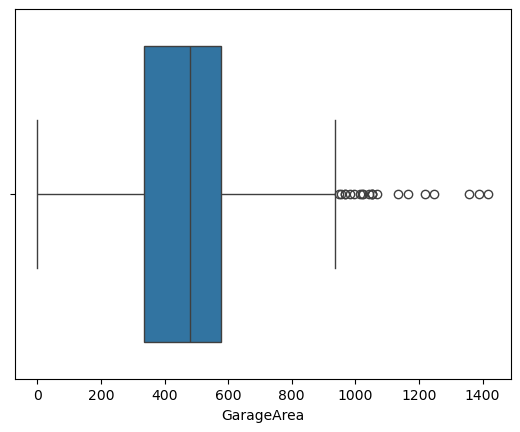

In [161]:
sns.boxplot(x="GarageArea",data=df)

<Axes: xlabel='GarageArea', ylabel='Density'>

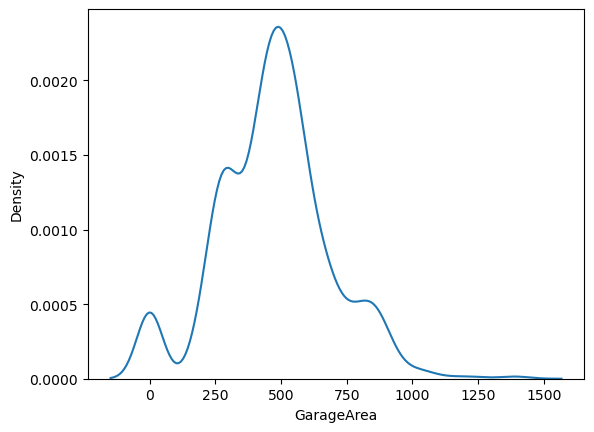

In [162]:
sns.kdeplot(data=df,x="GarageArea")

There seems be a right skew and outliers to be adressed towards the end of the tail. In the box plot you can see some outliers outside the range of the mean. You can also see a light elevation in zero due to properties with no garages.

In [163]:
col = "GarageArea"
mean = df[col].mean()
std = df[col].std()

lower = mean-3*std
upper = mean+3*std
outliers = df[(df[col]<lower)|(df[col]>upper)]
outliers

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3,HalfBath_0,HalfBath_1,HalfBath_2,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageCars_0,GarageCars_1,GarageCars_2,GarageCars_3
178,179,20,RL,-0.201196,1.344442,Pave,NaN,IR1,Lvl,AllPub,culdsac,Gtl,stonebr,Norm,Norm,1Fam,1Story,9,5,2008,2009,Hip,CompShg,VinylSd,VinylSd,Stone,748.0,Ex,TA,PConc,Ex,TA,No,GLQ,1904,Unf,0,312,2216,GasA,Ex,Y,SBrkr,2234,0,0,2234,1,0,2,0,1,1,Ex,9,Typ,1,Gd,Attchd,2009.0,Fin,3,1166,TA,TA,Y,0,60,0,0,0,0,NaN,NaN,NaN,0,7,2009,New,Partial,2.797203,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1
581,582,20,RL,1.129575,0.698704,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,nridght,Norm,Norm,1Fam,1Story,8,5,2008,2009,Hip,CompShg,VinylSd,VinylSd,BrkFace,306.0,Ex,TA,PConc,Ex,TA,No,Unf,0,Unf,0,2042,2042,GasA,Ex,Y,SBrkr,2042,0,0,2042,0,0,2,1,3,1,Ex,8,Typ,1,Gd,Attchd,2009.0,RFn,3,1390,TA,TA,Y,0,90,0,0,0,0,NaN,NaN,NaN,0,8,2009,New,Partial,1.061042,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,1
664,665,20,RL,-0.958138,1.716025,Pave,NaN,IR2,Lvl,AllPub,culdsac,Gtl,somerst,RRAn,Norm,1Fam,1Story,8,5,2005,2006,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,Gd,TA,PConc,Ex,TA,Mn,GLQ,1721,Unf,0,356,2077,GasA,Ex,Y,SBrkr,2097,0,0,2097,1,0,1,1,1,1,Ex,8,Typ,1,Ex,Attchd,2005.0,Fin,3,1134,TA,TA,Y,192,267,0,0,0,0,NaN,NaN,NaN,0,1,2006,New,Partial,2.363236,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,1
825,826,20,RL,1.585073,1.011302,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,nridght,PosN,PosN,1Fam,1Story,10,5,2007,2008,Hip,CompShg,CemntBd,CmentBd,BrkFace,816.0,E

Using the three standard deviation, to allow for more variety of data I will identify the outliers that we will winsorize.

In [164]:
df[col] = df[col].clip(upper,lower)

Winsorize the data, to allow for better analysis and that outliers do not interefere with exploration.

In [165]:
df["GarageArea"].skew()

0.055018612899627804

Skewness is effectively eliminated.

<Axes: xlabel='GarageArea', ylabel='SalePrice'>

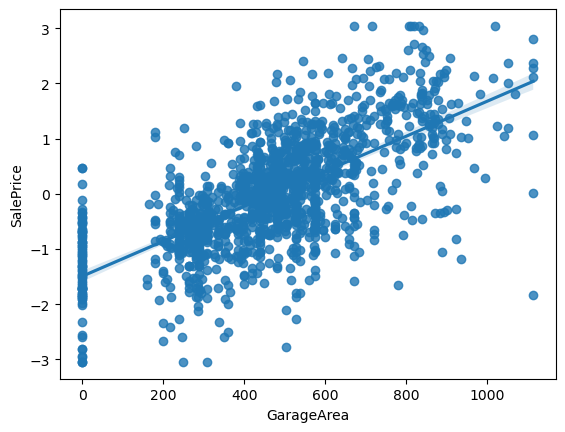

In [166]:
sns.regplot(x="GarageArea",y="SalePrice",data=df)

In [167]:
df["GarageArea"].corr(df["SalePrice"])

0.6666328569326527

Looking into the relationship there is a positive relationship as the GarageArea increases the SalePrice also increases. Plus, the co-rrelation index indicates a very strong correlation above 0.5 between the variables.

In [168]:
df["GarageArea"] = zscore(df.GarageArea)

Standardize the column that we just cleaned to avoid any bias in the exploration.

In [169]:
df_model = pd.concat([df_model,df['GarageArea']],axis=1)

## 20. GarageQual

In [170]:
df["GarageQual"].isna().sum()

81

Check for null values, we have to clean 81 null values.

<Axes: xlabel='GarageQual', ylabel='count'>

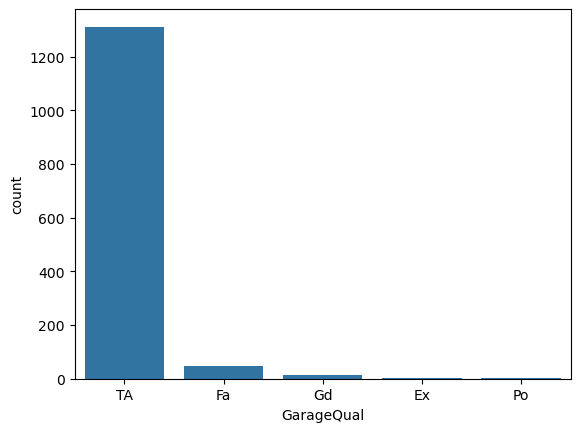

In [171]:
sns.countplot(x="GarageQual",data=df)

Possible under-representation of 'Ex' and 'Po'.

In [172]:
df["GarageQual"] = df["GarageQual"].fillna("None")
df["GarageQual"].value_counts(dropna=False)

GarageQual
TA      1311
None      81
Fa        48
Gd        14
Ex         3
Po         3
Name: count, dtype: int64

Since null values represent Houses that do not have a Garage we just create a new category for this type of houses. Then assign 'Ex' and 'Po' to other categories as they are under-represented.

In [173]:
df.loc["Ex"==df["GarageQual"],"GarageQual"] = "Gd"
df.loc["Po"==df["GarageQual"],"GarageQual"] = "Fa"
df["GarageQual"].value_counts(dropna=False)

GarageQual
TA      1311
None      81
Fa        51
Gd        17
Name: count, dtype: int64

Assign 'Ex' to 'Po' to 'Gd' and 'Fa' respectively, since this are ordinal values we assign them to the level directly above.

<Axes: xlabel='GarageQual', ylabel='SalePrice'>

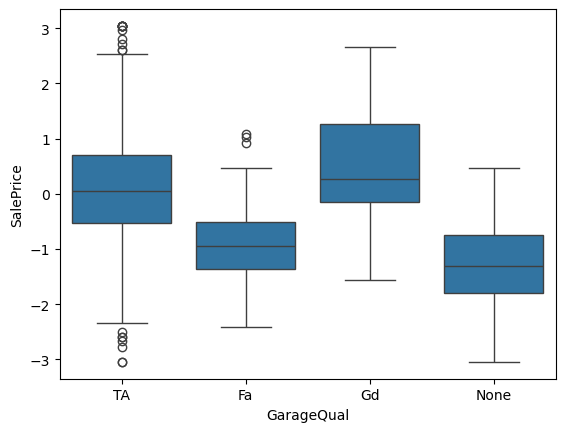

In [174]:
sns.boxplot(x="GarageQual",y="SalePrice",data=df)

Bivariate exploration shows that the quality of Garage can influence the SalePrice with None having low SalePrice and Good having the highest prices.

In [175]:
dummies= pd.get_dummies(df["GarageQual"],prefix="GarageQual",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3,HalfBath_0,HalfBath_1,HalfBath_2,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageCars_0,GarageCars_1,GarageCars_2,GarageCars_3,GarageQual_Fa,GarageQual_Gd,GarageQual_None,GarageQual_TA
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,0.359263,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,-0.057853,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,0.643660,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1
3,4,70,RL,-0.348149,0.115314,Pave,NaN,IR1,Lvl,AllPub,corner,Gtl,crawfor,Norm

One-hot encode the categorical values for machine learning exploration after 'GarageQual' has been cleaned and then add it to the dataframe.

In [176]:
df_model = pd.concat([df_model,dummies],axis=1)

## 21. GrLivArea

In [177]:
df['GrLivArea'].isna().sum()

0

In [178]:
df["GrLivArea"].agg(['min','mean','median','max','std'])

min        334.000000
mean      1515.463699
median    1464.000000
max       5642.000000
std        525.480383
Name: GrLivArea, dtype: float64

In [179]:
df["GrLivArea"].skew()

1.3665603560164552

<Axes: xlabel='GrLivArea'>

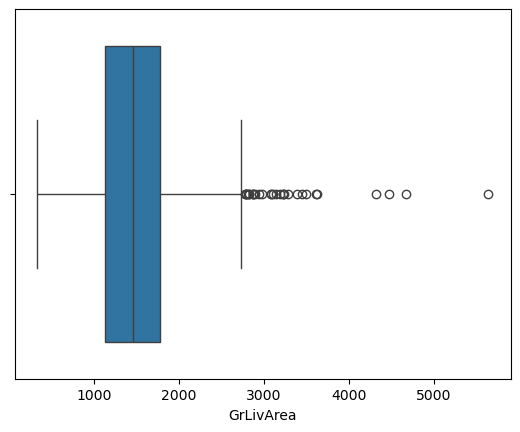

In [180]:
sns.boxplot(x="GrLivArea",data=df)

<Axes: xlabel='GrLivArea', ylabel='Density'>

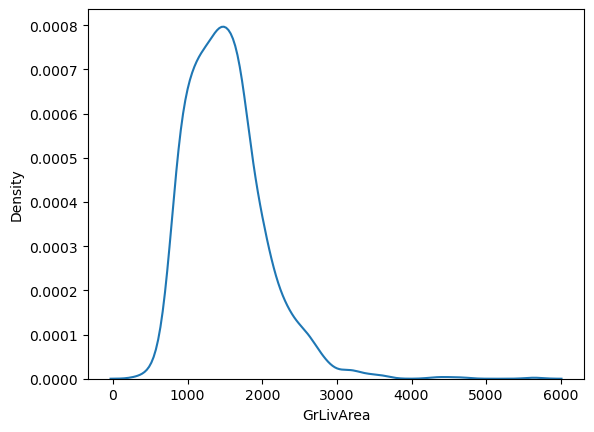

In [181]:
sns.kdeplot(x="GrLivArea",data=df)

<Axes: xlabel='GrLivArea', ylabel='Density'>

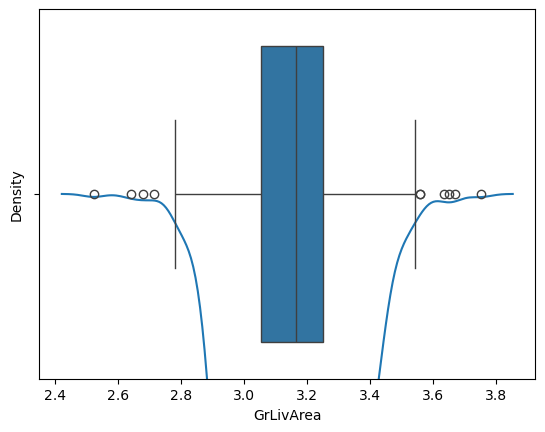

In [182]:
df["GrLivArea"] = np.log10(df["GrLivArea"])
sns.kdeplot(data=df,x="GrLivArea")
display()
sns.boxplot(data=df,x="GrLivArea")

In [183]:
col = "GrLivArea"
mean = df[col].mean()
std = df[col].std()

lower = mean-3*std
upper = mean+3*std
outliers = df[(df[col]<lower)|(df[col]>upper)]
outliers

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3,HalfBath_0,HalfBath_1,HalfBath_2,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageCars_0,GarageCars_1,GarageCars_2,GarageCars_3,GarageQual_Fa,GarageQual_Gd,GarageQual_None,GarageQual_TA
29,30,30,RM,-0.348149,-0.727319,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,brkside,Feedr,RRNn,1Fam,1Story,4,6,1927,1950,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0,Unf,0,520,520,GasA,Fa,N,SBrkr,520,0,0,2.716003,0,0,1,0,1,1,Fa,4,Typ,0,None,Detchd,1920.0,Unf,1,-1.100641,Fa,TA,Y,49,0,87,0,0,0,NaN,NaN,NaN,0,5,2008,WD,Normal,-2.259575,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0
523,524,60,RL,1.980648,3.048223,Pave,NaN,IR1,Bnk,AllPub,inside,Gtl,edwards,PosN,PosN,1Fam,2Story,10,5,2007,2008,Hip,CompShg,CemntBd,CmentBd,Stone,762.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,2260,Unf,0,878,3138,GasA,Ex,Y,SBrkr,3138,1538,0,3.669875,1,0,3,1,3,1,Ex,11,Typ,1,Gd,BuiltIn,2007.0,Fin,3,1.951885,TA,TA,Y,208,406,0,0,0,0,NaN,NaN,NaN,0,10,2007,New,Partial,2.173213,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1
533,534,20,RL,-0.897289,-1.207551,Pave,NaN,Reg,Low,AllPub,inside,Mod,brkside,Norm,Norm,1Fam,1Story,3,3,1946,1950,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,Fa,Fa,Slab,NaN,NaN,NaN,NaN,0,NaN,0,0,0,GasA,Fa,N,FuseF,334,0,0,2.523746,0,0,1,0,1,1,Fa,2,Typ,0,None,None,NaN,None,0,-2.238228,None,NaN,N,0,0,0,0,0,0,NaN,NaN,NaN,0,1,2007,WD,Normal,-3.043935,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,1,0
691,692,60,RL,1.308554,1.777602,Pave,NaN,IR1,Lvl,AllP

In [184]:
df[col] = df[col].clip(upper,lower)

In [185]:
df["GrLivArea"].skew()

-0.005676806427245859

<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

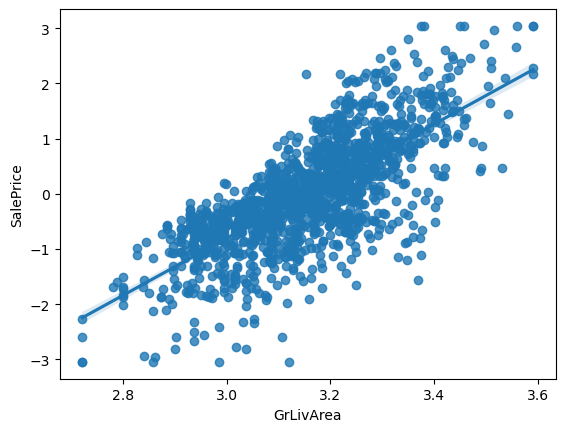

In [186]:
sns.regplot(x="GrLivArea",y="SalePrice",data=df)

In [187]:
df["GrLivArea"].corr(df["SalePrice"])

0.7390865688269916

In [188]:
df["GrLivArea"] = zscore(df.GrLivArea)

In [189]:
df_model = pd.concat([df_model,df['GrLivArea']],axis=1)

## 22. TotalBsmtSF

In [190]:
df['TotalBsmtSF'].isna().sum()

0

In [191]:
df['TotalBsmtSF'].dtype

dtype('int64')

In [192]:
df["TotalBsmtSF"].agg(['min','mean','median','max','std'])

min          0.000000
mean      1057.429452
median     991.500000
max       6110.000000
std        438.705324
Name: TotalBsmtSF, dtype: float64

In [193]:
df["TotalBsmtSF"].skew()

1.5242545490627664

<Axes: xlabel='TotalBsmtSF'>

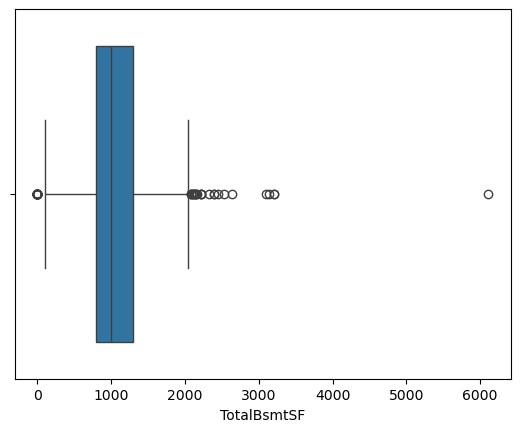

In [194]:
sns.boxplot(x="TotalBsmtSF",data=df)

<Axes: xlabel='TotalBsmtSF', ylabel='Density'>

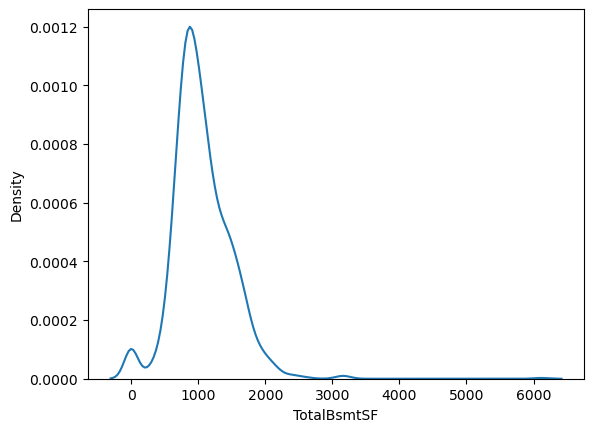

In [195]:
sns.kdeplot(x="TotalBsmtSF",data=df)

In [196]:
df['TotalBsmtSF'] = np.sqrt(df['TotalBsmtSF'])

In [197]:
print(df['TotalBsmtSF'].agg(['min','mean', 'median','max','std']).round(2))

min        0.00
mean      31.59
median    31.49
max       78.17
std        7.70
Name: TotalBsmtSF, dtype: float64


In [198]:
print(df.TotalBsmtSF.isna().sum())

0


<Axes: xlabel='TotalBsmtSF'>

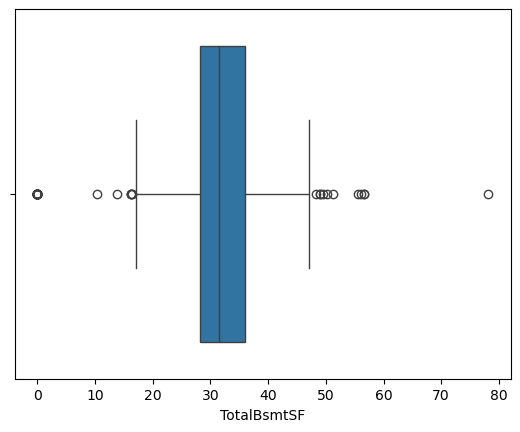

In [199]:
sns.boxplot(x='TotalBsmtSF',data=df)

<Axes: xlabel='TotalBsmtSF', ylabel='Density'>

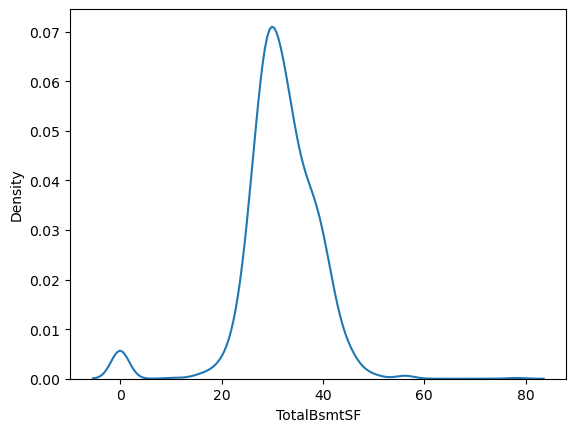

In [200]:
sns.kdeplot(x='TotalBsmtSF',data=df)

In [201]:
df['TotalBsmtSF'].skew()

-1.2745373951324759

In [202]:
col = "TotalBsmtSF"
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_mask = (df[col] < lower) | (df[col] > upper)
outliers = df.loc[outlier_mask]

df["TotalBsmtSF"] = df["TotalBsmtSF"].clip(lower, upper)

In [203]:
df['TotalBsmtSF'].skew()

-0.028801254044461832

<Axes: xlabel='TotalBsmtSF', ylabel='Density'>

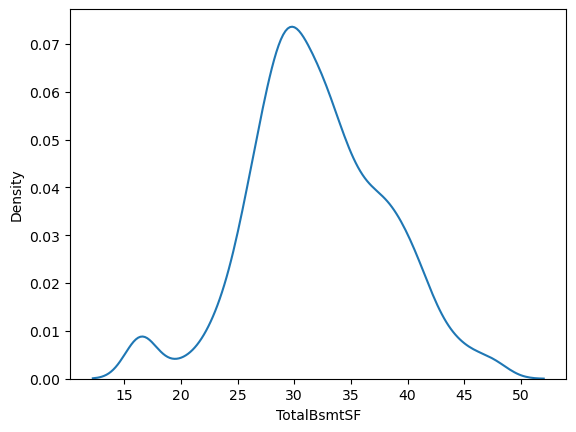

In [204]:
sns.kdeplot(data=df,x="TotalBsmtSF")

In [205]:
df["TotalBsmtSF"].skew()

-0.028801254044461832

In [206]:
df["TotalBsmtSF"] = zscore(df.TotalBsmtSF)

-0.02880125404446344


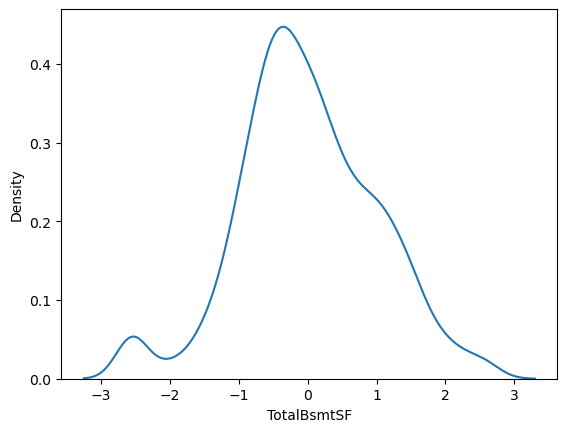

In [207]:
sns.kdeplot(data=df,x="TotalBsmtSF")
print(df["TotalBsmtSF"].skew())

In [208]:
df_model["TotalBsmtSF"] = df.loc[df_model.index, "TotalBsmtSF"]

## 23. HouseAge

In [209]:
df['HouseAge'] = df['YrSold'] - df['YearBuilt']

In [210]:
df["HouseAge"].isna().sum()

0

In [211]:
df["HouseAge"].agg(['min','mean','median','max','std'])

min         0.000000
mean       36.547945
median     35.000000
max       136.000000
std        30.250152
Name: HouseAge, dtype: float64

In [212]:
df["HouseAge"].skew()

0.609030229450241

<Axes: xlabel='HouseAge', ylabel='Density'>

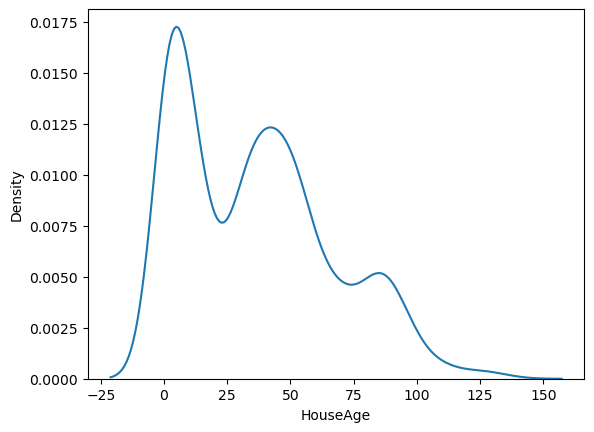

In [213]:
sns.kdeplot(x="HouseAge",data=df)

<Axes: xlabel='HouseAge'>

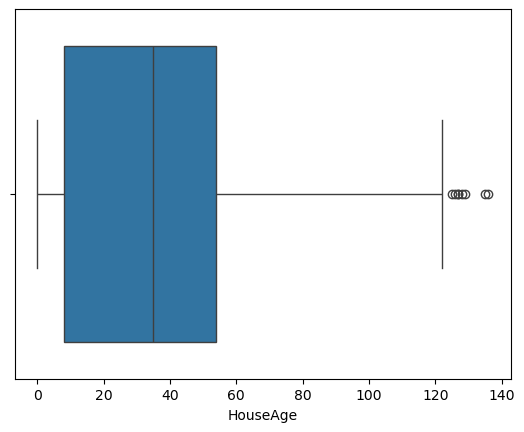

In [214]:
sns.boxplot(x="HouseAge",data=df)

In [215]:
df["HouseAge"] = np.sqrt(df['HouseAge'])

<Axes: xlabel='HouseAge', ylabel='Density'>

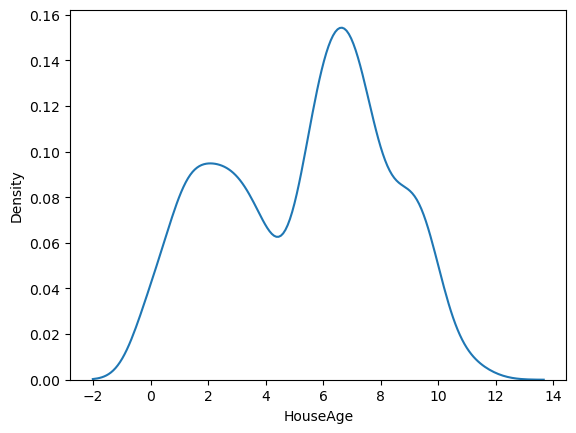

In [216]:
sns.kdeplot(x="HouseAge",data=df)

<Axes: xlabel='HouseAge'>

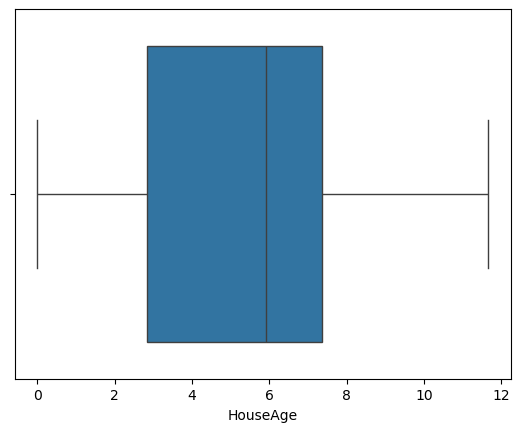

In [217]:
sns.boxplot(x="HouseAge",data=df)

In [218]:
df['HouseAge'].skew()

-0.17748917770160472

In [219]:
col = "HouseAge"
mean = df[col].mean()
std = df[col].std()

lower = mean-3*std
upper = mean+3*std
outliers = df[(df[col]<lower)|(df[col]>upper)]
outliers

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3,HalfBath_0,HalfBath_1,HalfBath_2,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageCars_0,GarageCars_1,GarageCars_2,GarageCars_3,GarageQual_Fa,GarageQual_Gd,GarageQual_None,GarageQual_TA,HouseAge


In [220]:
df[col] = df[col].clip(upper,lower)

In [221]:
df["HouseAge"].skew()

-0.17748917770160472

<Axes: xlabel='HouseAge', ylabel='SalePrice'>

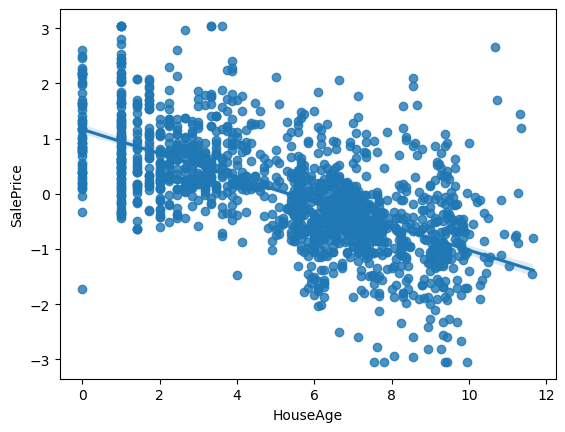

In [222]:
sns.regplot(x='HouseAge',y='SalePrice',data=df)

In [223]:
df["HouseAge"].corr(df["SalePrice"])

-0.6290580032208696

In [224]:
df["HouseAge"] = zscore(df["HouseAge"])

In [225]:
df_model = pd.concat([df_model,df['HouseAge']],axis=1)

## 24. GarageCond

In [226]:
df['GarageCond']

0       TA
1       TA
2       TA
3       TA
4       TA
        ..
1455    TA
1456    TA
1457    TA
1458    TA
1459    TA
Name: GarageCond, Length: 1460, dtype: object

In [227]:
df['GarageCond'].isna().sum()

81

GarageCond
TA      1326
None      81
Fa        35
Gd         9
Po         7
Ex         2
Name: count, dtype: int64

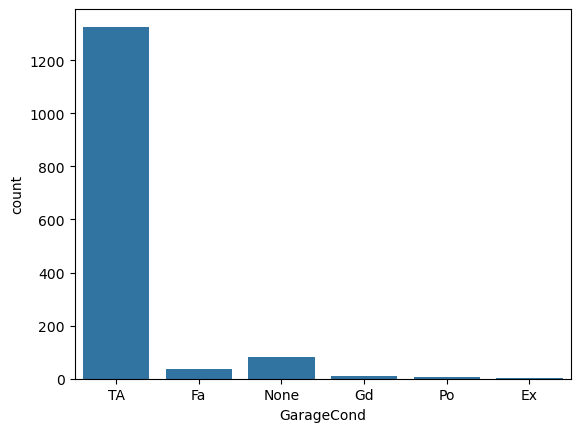

In [228]:
df['GarageCond']= df["GarageCond"].fillna("None")
sns.countplot(x= 'GarageCond', data= df)
df['GarageCond'].value_counts()

<Axes: xlabel='GarageCond', ylabel='SalePrice'>

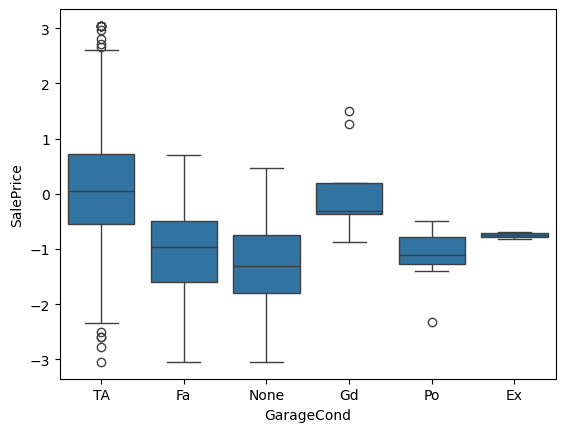

In [229]:
sns.boxplot(x="GarageCond",y="SalePrice",data=df)

In [230]:
dummies= pd.get_dummies(df["GarageCond"],prefix="GarageCond",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3,HalfBath_0,HalfBath_1,HalfBath_2,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageCars_0,GarageCars_1,GarageCars_2,GarageCars_3,GarageQual_Fa,GarageQual_Gd,GarageQual_None,GarageQual_TA,HouseAge,GarageCond_Ex,GarageCond_Fa,GarageCond_Gd,GarageCond_None,GarageCond_Po,GarageCond_TA
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,-0.446126,GasA,Ex,Y,SBrkr,856,854,0,0.535199,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,0.359263,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,-1.067967,0,0,0,0,0,1
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,0.585831,GasA,Ex,Y,SBrkr,1262,0,0,-0.385976,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,-0.057853,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0.087976,0,0,0,0,0,1
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,-0.269276,GasA,Ex,Y,SBrkr,920,866,0,0.667055,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,0.643660,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0

In [231]:
df_model = pd.concat([df_model,dummies],axis=1)

## 25. PavedDrive

In [232]:
df['PavedDrive'].isna().sum()

0

In [233]:
df['PavedDrive']

0       Y
1       Y
2       Y
3       Y
4       Y
       ..
1455    Y
1456    Y
1457    Y
1458    Y
1459    Y
Name: PavedDrive, Length: 1460, dtype: object

<Axes: xlabel='PavedDrive', ylabel='count'>

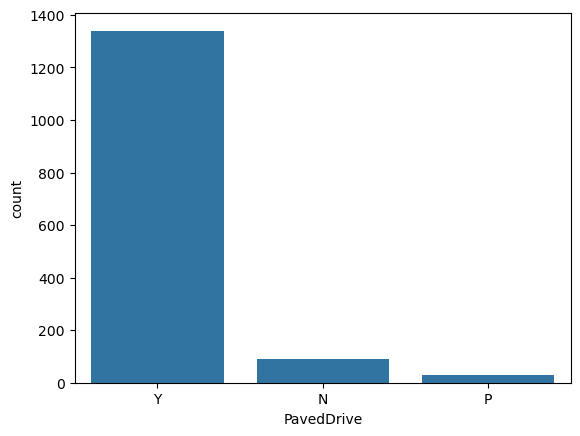

In [234]:
sns.countplot(x="PavedDrive",data=df)

<Axes: xlabel='PavedDrive', ylabel='SalePrice'>

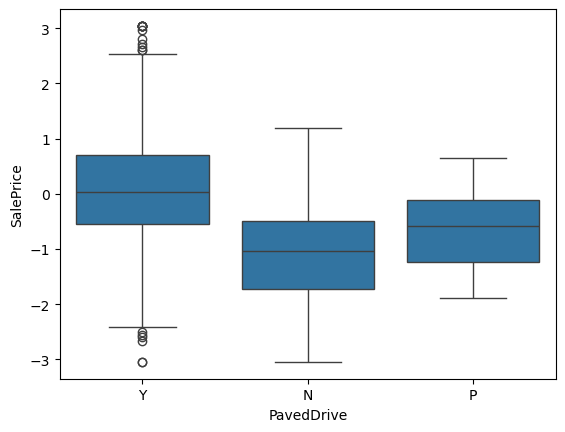

In [235]:
sns.boxplot(x="PavedDrive",y="SalePrice",data=df)

In [236]:
dummies= pd.get_dummies(df["PavedDrive"],prefix="PavedDrive",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3,HalfBath_0,HalfBath_1,HalfBath_2,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageCars_0,GarageCars_1,GarageCars_2,GarageCars_3,GarageQual_Fa,GarageQual_Gd,GarageQual_None,GarageQual_TA,HouseAge,GarageCond_Ex,GarageCond_Fa,GarageCond_Gd,GarageCond_None,GarageCond_Po,GarageCond_TA,PavedDrive_N,PavedDrive_P,PavedDrive_Y
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,-0.446126,GasA,Ex,Y,SBrkr,856,854,0,0.535199,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,0.359263,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,-1.067967,0,0,0,0,0,1,0,0,1
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,0.585831,GasA,Ex,Y,SBrkr,1262,0,0,-0.385976,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,-0.057853,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0.087976,0,0,0,0,0,1,0,0,1
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,-0.269276,GasA,Ex,Y,SBrkr,920,866,0,0.667055,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,0.643660,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,0.743291,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,

In [237]:
df_model = pd.concat([df_model,dummies],axis=1)

## 26. 1stFlrSF

In [238]:
df['1stFlrSF'].isna().sum()

0

In [239]:
df['1stFlrSF']

0        856
1       1262
2        920
3        961
4       1145
        ... 
1455     953
1456    2073
1457    1188
1458    1078
1459    1256
Name: 1stFlrSF, Length: 1460, dtype: int64

In [240]:
df["1stFlrSF"].agg(['min','mean','median','max','std'])

min        334.000000
mean      1162.626712
median    1087.000000
max       4692.000000
std        386.587738
Name: 1stFlrSF, dtype: float64

In [241]:
df["1stFlrSF"].skew()

1.3767566220336365

<Axes: xlabel='1stFlrSF', ylabel='Density'>

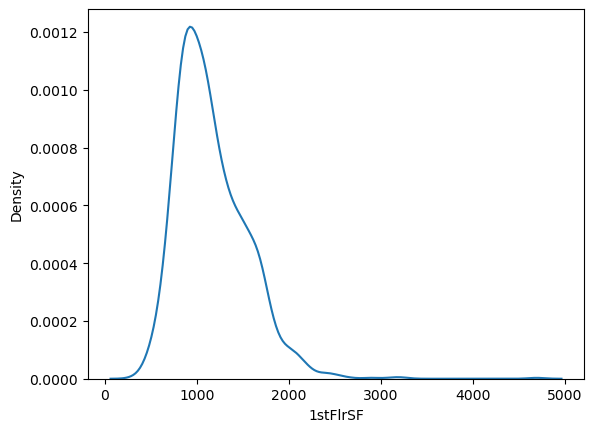

In [242]:
sns.kdeplot(x="1stFlrSF",data=df)

<Axes: xlabel='1stFlrSF'>

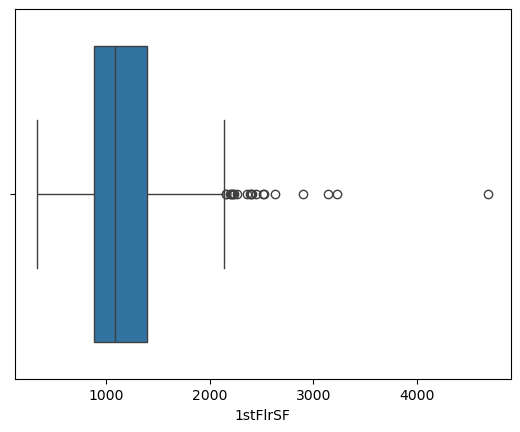

In [243]:
sns.boxplot(x="1stFlrSF",data=df)

In [244]:
df["1stFlrSF"] = np.sqrt(df["1stFlrSF"])

<Axes: xlabel='1stFlrSF', ylabel='Density'>

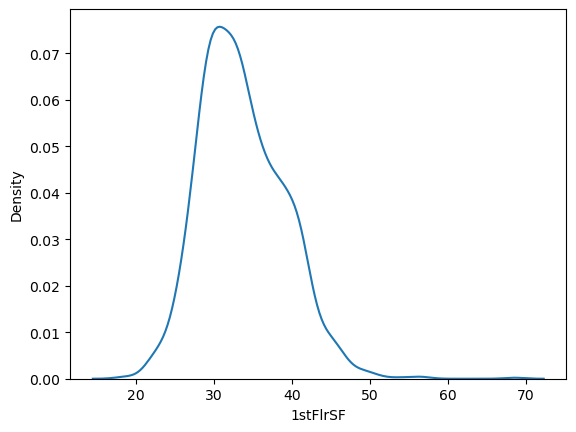

In [245]:
sns.kdeplot(x='1stFlrSF',data=df)

<Axes: xlabel='1stFlrSF'>

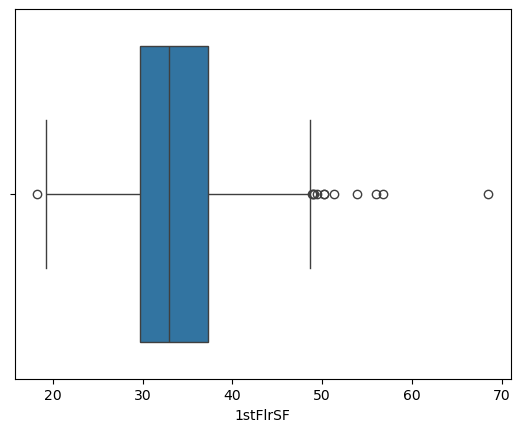

In [246]:
sns.boxplot(x='1stFlrSF',data=df)

In [247]:
df['1stFlrSF'].skew()

0.6242627120029303

In [248]:
col = "1stFlrSF"
mean = df[col].mean()
std = df[col].std()

lower = mean-3*std
upper = mean+3*std
outliers = df[(df[col]<lower)|(df[col]>upper)]
outliers

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3,HalfBath_0,HalfBath_1,HalfBath_2,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageCars_0,GarageCars_1,GarageCars_2,GarageCars_3,GarageQual_Fa,GarageQual_Gd,GarageQual_None,GarageQual_TA,HouseAge,GarageCond_Ex,GarageCond_Fa,GarageCond_Gd,GarageCond_None,GarageCond_Po,GarageCond_TA,PavedDrive_N,PavedDrive_P,PavedDrive_Y
496,497,20,RL,0.605931,0.696772,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,noridge,Norm,Norm,1Fam,1Story,8,5,1992,1993,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,PConc,Gd,TA,No,GLQ,1231,Unf,0,1969,2.601264,GasA,Ex,Y,SBrkr,56.815491,0,0,2.461778,1,0,3,0,4,1,Gd,10,Typ,1,Gd,Attchd,1992.0,RFn,2,0.349783,TA,TA,Y,264,75,291,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,2.404913,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,-0.500034,0,0,0,0,0,1,0,0,1
523,524,60,RL,1.980648,3.048223,Pave,NaN,IR1,Bnk,AllPub,inside,Gtl,edwards,PosN,PosN,1Fam,2Story,10,5,2007,2008,Hip,CompShg,CemntBd,CmentBd,Stone,762.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,2260,Unf,0,878,2.601264,GasA,Ex,Y,SBrkr,56.017854,1538,0,3.034284,1,0,3,1,3,1,Ex,11,Typ,1,Gd,BuiltIn,2007.0,Fin,3,1.951885,TA,TA,Y,208,406,0,0,0,0,NaN,NaN,NaN,0,10,2007,New,Partial,2.173213,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,-1.843779,0,0,0,0,0,1,0,0,1
529,530,20,RL,1.583372,2.629490,Pave,NaN,IR1,Lvl,AllPub,culdsac,Gtl,crawfor,Norm,Norm,1Fam,1Story,6,3,1957,1975,Hip,CompShg,Wd Sdng,Stone,NaN,NaN,Gd,TA,PConc,TA,TA,No,Rec,1219,Unf,0,816,2.164327,GasA,TA,Y,SBrkr,50.149776,0,0,1.704967,1,0,3,0,4,2,TA,9,Maj1,2,TA,Attchd,1975.0,RFn,2,0.055906,TA,TA,Y,0,0,200,0,0,0,NaN,NaN,NaN,0,3,2007,WD,Alloca,0.469105,0,0,0,0,1,0,0,0,0,

In [249]:
df[col] = df[col].clip(upper,lower)

In [250]:
df["1stFlrSF"].skew()

0.4099157846324938

<Axes: xlabel='1stFlrSF', ylabel='SalePrice'>

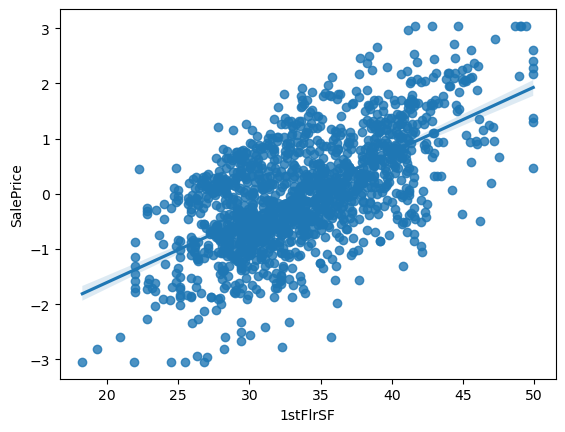

In [251]:
sns.regplot(x="1stFlrSF",y="SalePrice",data=df)

In [252]:
df["1stFlrSF"].corr(df["SalePrice"])

0.6258079851254632

In [253]:
df["1stFlrSF"] = zscore(df['1stFlrSF'])

In [254]:
df_model = pd.concat([df_model,df['1stFlrSF']],axis=1)

## 27. OverallCond

In [255]:
df['OverallCond'].isna().sum()

0

In [256]:
df['OverallCond'].dtype

dtype('int64')

In [257]:
df['OverallCond'] =df['OverallCond'].astype('str')

<Axes: xlabel='OverallCond', ylabel='count'>

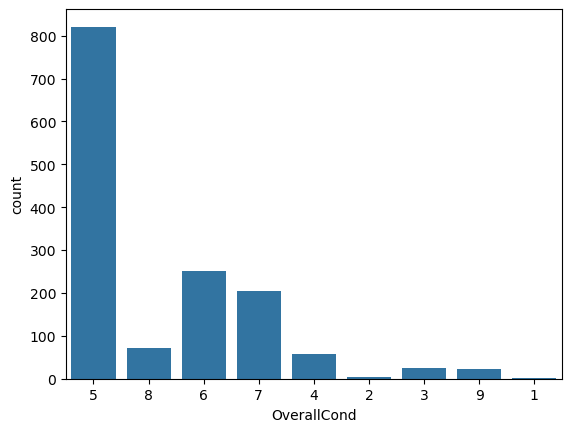

In [258]:
sns.countplot(x="OverallCond",data=df)

In [259]:
df['OverallCond'].value_counts()

OverallCond
5    821
6    252
7    205
8     72
4     57
3     25
9     22
2      5
1      1
Name: count, dtype: int64

In [260]:
df.loc["1"==df["OverallCond"],"OverallCond"] = "3"
df.loc["2"==df["OverallCond"],"OverallCond"] = "3"

In [261]:
df['OverallCond'].value_counts()

OverallCond
5    821
6    252
7    205
8     72
4     57
3     31
9     22
Name: count, dtype: int64

<Axes: xlabel='OverallCond', ylabel='SalePrice'>

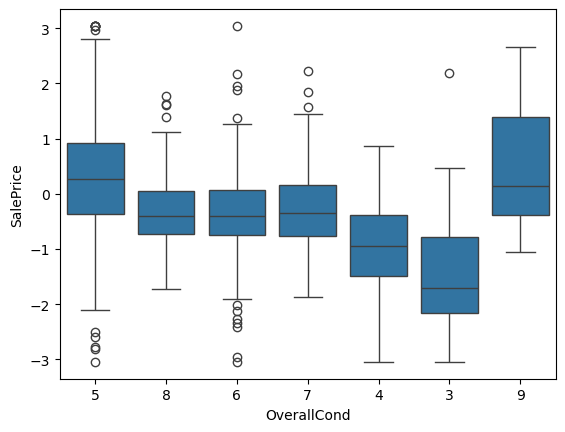

In [262]:
sns.boxplot(x="OverallCond",y="SalePrice",data=df)

In [263]:
dummies= pd.get_dummies(df["OverallCond"],prefix="OverallCond",dtype="int")
df = pd.concat([df,dummies],axis=1)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotConfig_corner,LotConfig_culdsac,LotConfig_fr2,LotConfig_inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_blmngtn,Neighborhood_brdale,Neighborhood_brkside,Neighborhood_clearcr,Neighborhood_collgcr,Neighborhood_crawfor,Neighborhood_edwards,Neighborhood_gilbert,Neighborhood_idotrr,Neighborhood_meadowv,Neighborhood_mitchel,Neighborhood_names,Neighborhood_noridge,Neighborhood_nridght,Neighborhood_nwames,Neighborhood_oldtown,Neighborhood_sawyer,Neighborhood_sawyerw,Neighborhood_somerst,Neighborhood_stonebr,Neighborhood_swisu,Neighborhood_timber,Neighborhood_veenker,OverallQual_10,OverallQual_3,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,Fireplaces_0,Fireplaces_1,Fireplaces_2,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BsmtFullBath_0,BsmtFullBath_1,BsmtFullBath_2,BsmtHalfBath_0,BsmtHalfBath_1,FullBath_1,FullBath_2,FullBath_3,HalfBath_0,HalfBath_1,HalfBath_2,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageCars_0,GarageCars_1,GarageCars_2,GarageCars_3,GarageQual_Fa,GarageQual_Gd,GarageQual_None,GarageQual_TA,HouseAge,GarageCond_Ex,GarageCond_Fa,GarageCond_Gd,GarageCond_None,GarageCond_Po,GarageCond_TA,PavedDrive_N,PavedDrive_P,PavedDrive_Y,OverallCond_3,OverallCond_4,OverallCond_5,OverallCond_6,OverallCond_7,OverallCond_8,OverallCond_9
0,1,60,RL,-0.107065,-0.134855,Pave,NaN,Reg,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,-0.446126,GasA,Ex,Y,SBrkr,-0.824206,854,0,0.535199,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,0.359263,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,0.566883,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,-1.067967,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0
1,2,20,RL,0.518331,0.125989,Pave,NaN,Reg,Lvl,AllPub,fr2,Gtl,veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,0.585831,GasA,Ex,Y,SBrkr,0.354962,0,0,-0.385976,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,-0.057853,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,0.214731,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0.087976,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0
2,3,60,RL,0.028834,0.450223,Pave,NaN,IR1,Lvl,AllPub,inside,Gtl,collgcr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,-0.269276,GasA,Ex,Y,SBrkr,-0.622128,866,0,0.667055,1,0,2,1,3,1,Gd,6,T

In [264]:
df_model = pd.concat([df_model,dummies],axis=1)

## 28. KitchenQual

In [265]:
df['KitchenQual'].isna().sum()

0

<Axes: xlabel='KitchenQual', ylabel='count'>

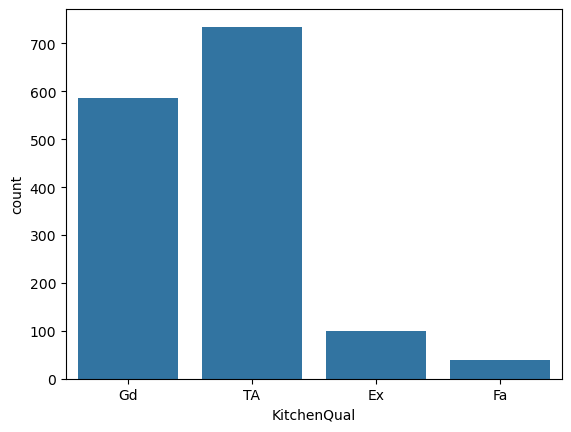

In [266]:
sns.countplot(x="KitchenQual",data=df)

In [267]:
df['KitchenQual'].value_counts()

KitchenQual
TA    735
Gd    586
Ex    100
Fa     39
Name: count, dtype: int64

In [268]:
dummies= pd.get_dummies(df["KitchenQual"],prefix="KitchenQual",dtype="int")
df = pd.concat([df,dummies],axis=1)
df
df_model = pd.concat([df_model,dummies],axis=1)

## 29. BsmtQual

In [269]:
df['BsmtQual']

0       Gd
1       Gd
2       Gd
3       TA
4       Gd
        ..
1455    Gd
1456    Gd
1457    TA
1458    TA
1459    TA
Name: BsmtQual, Length: 1460, dtype: object

In [270]:
df['BsmtQual'].isna().sum()

37

In [271]:
df["BsmtQual"] = df["BsmtQual"].fillna("None")
df["BsmtQual"].value_counts(dropna=False)

BsmtQual
TA      649
Gd      618
Ex      121
None     37
Fa       35
Name: count, dtype: int64

<Axes: xlabel='BsmtQual', ylabel='SalePrice'>

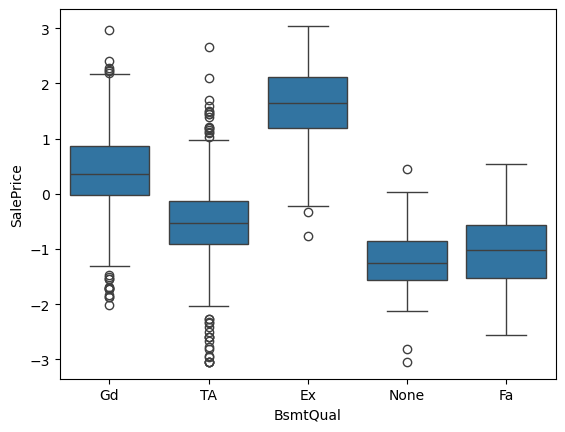

In [272]:
sns.boxplot(x="BsmtQual",y="SalePrice",data=df)

In [273]:
dummies= pd.get_dummies(df["BsmtQual"],prefix="BsmtQual",dtype="int")
df = pd.concat([df,dummies],axis=1)
df
df_model = pd.concat([df_model,dummies],axis=1)

## 30. AgeRemod

In [274]:
df["AgeRemod"] = (df["YrSold"] - df["YearRemodAdd"]).values

In [275]:
df['AgeRemod'].isna().sum()

0

In [276]:
df['AgeRemod'].dtype

dtype('int64')

In [277]:
df["AgeRemod"].agg(['min','mean','median','max','std'])

min       -1.000000
mean      22.950000
median    14.000000
max       60.000000
std       20.640653
Name: AgeRemod, dtype: float64

In [278]:
df["AgeRemod"].skew()

0.5024890321999378

<Axes: xlabel='AgeRemod', ylabel='Density'>

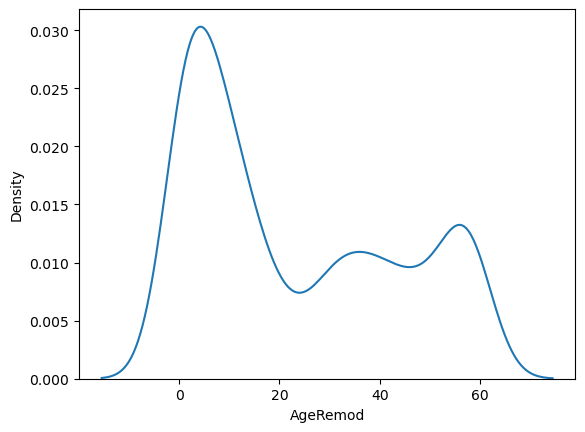

In [279]:
sns.kdeplot(x="AgeRemod",data=df)

<Axes: xlabel='AgeRemod'>

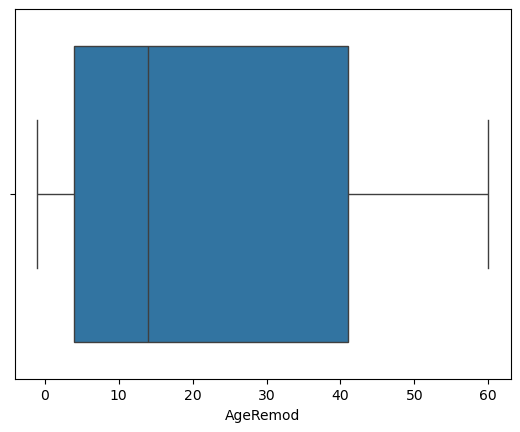

In [280]:
sns.boxplot(x='AgeRemod',data=df)

In [281]:
df.loc[df['AgeRemod'] < 0, 'AgeRemod'] = 0

In [282]:
df["AgeRemod"] = np.sqrt(df['AgeRemod'])

<Axes: xlabel='AgeRemod', ylabel='Density'>

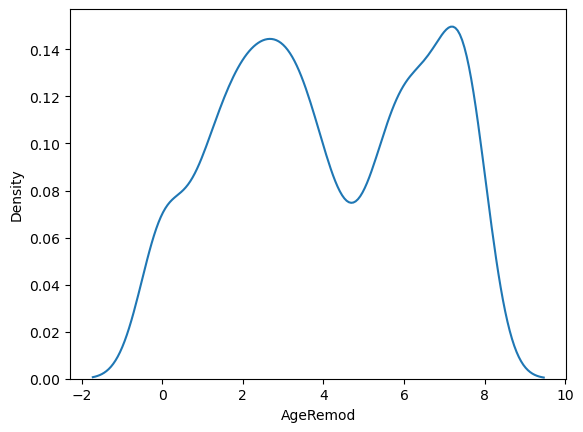

In [283]:
sns.kdeplot(data=df["AgeRemod"])

In [284]:
col = "AgeRemod"
mean = df[col].mean()
std = df[col].std()

lower = mean-3*std
upper = mean+3*std
outliers = df[(df[col]<lower)|(df[col]>upper)]
outliers
df[col] = df[col].clip(upper,lower)

In [285]:
df["AgeRemod"].skew()

-0.04590825087592455

<Axes: xlabel='AgeRemod', ylabel='SalePrice'>

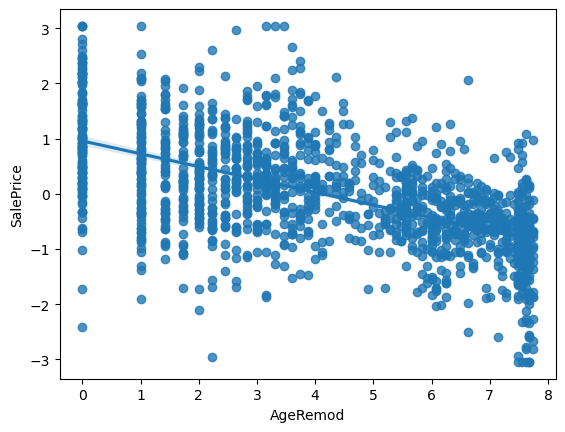

In [286]:
sns.regplot(x="AgeRemod",y="SalePrice",data=df)

In [287]:
df["SalePrice"].corr(df["AgeRemod"])

-0.5721005975694436

In [288]:
df["AgeRemod"] = zscore(df.AgeRemod)
df_model = pd.concat([df_model,df['AgeRemod']],axis=1)

## Exploration Process columns 21-30

Initially, general living area had a normal distribution but it was skewed. Did a log10 transformation and then winsorized outliers using 3 std method, standardized later. For total basement square footed it had normal skewness so winsorized outliers directly and standardized. For house age there is no normal distribution so I directly applied a square root non-linear transformation, winsorized, and standardized it. House age later is a column that directly measures the years old of a property by subtracting year sold and year built, this column did not have a normal distribution, so I did a non-linear transformation with the square root, later winsorized  and standardized it. For GarageCondition, filled the NA’s with ‘None’, since there was not under-representation of any variables directly hot encoded the variables. For paved drive, no under-representation so directly hot encoded the column. For First floor square footed did a non-linear transformation to reduce skewness, winsorized and then standardized it. No NA’s in overall condition, there was under-representation of some values which i re assigned to the level directly above, hot encoded the dummies. Kitchen quality no issues so directly hot encoded the column. For basement quality there was a lot of NA’s that I replaced with ‘None’ and then hot encoded the values. For the final column, did a calculation of year sold and year remodeled to capture the value of remodeling, There was a lot of negative values that I directly re assign them to 0, later identified outliers, winsorized and finally standardized.

## Heatmap exploration

In [289]:
DataTrim = df[["SalePrice","MSSubClass","LotFrontage","LotArea","LotConfig","LandSlope","Neighborhood","OverallQual","ExterQual","Fireplaces","FireplaceQu",
             "BsmtFullBath","BsmtHalfBath","FullBath","HalfBath","GarageType","GarageFinish","GarageCars","GarageArea","GarageQual"]]

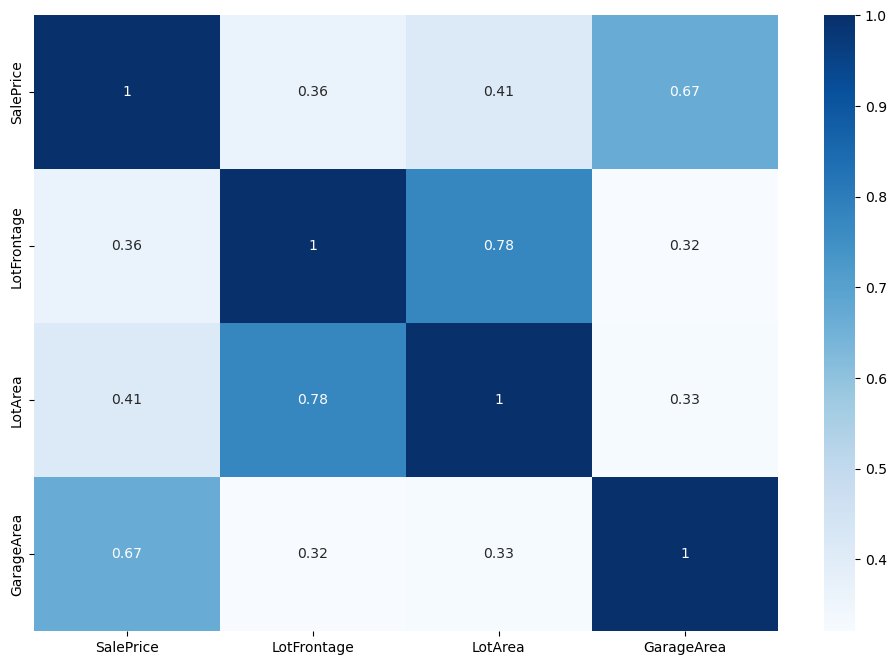

In [290]:
numeric_cols = DataTrim.select_dtypes(include=["number",'integer'])
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_cols.corr(),annot=True,cmap='Blues')
plt.show()

In [291]:
results = []
for col in DataTrim.columns:
    if col == "SalePrice":
        continue
    
    if DataTrim[col].dtype in ["int64", "float64"]:
        corr = DataTrim[[col, "SalePrice"]].corr().iloc[0,1]
    else:
        dummies = pd.get_dummies(DataTrim[col], drop_first=True)
        corr = dummies.apply(lambda x: x.corr(DataTrim["SalePrice"])).abs().max()
    results.append((col, corr))
corr_df = pd.DataFrame(results, columns=["Column", "Correlation"])
corr_df = corr_df.sort_values(by="Correlation", ascending=False)

print(corr_df)

          Column  Correlation
17    GarageArea     0.666633
7      ExterQual     0.602358
16    GarageCars     0.527224
9    FireplaceQu     0.515889
12      FullBath     0.511366
15  GarageFinish     0.439487
6    OverallQual     0.430314
2        LotArea     0.414336
0     MSSubClass     0.407327
14    GarageType     0.406615
8     Fireplaces     0.400855
1    LotFrontage     0.364280
5   Neighborhood     0.353402
13      HalfBath     0.334124
18    GarageQual     0.330996
10  BsmtFullBath     0.231189
3      LotConfig     0.147764
4      LandSlope     0.029805
11  BsmtHalfBath     0.008185


## Top 15 variables with strongest association to SalePrice
1. GarageArea
2. ExterQual
3. GarageCars
4. FireplaceQu
5. FullBath
6. GarageFinish
7. OverallQual
8. LotArea
9. GarageType
10. MSSubClass
11. Fireplaces
12. LotFrontage
13. Neighborhood
14. HalfBath
15. GarageQual

# PART 2: Linear Regression Modeling

In [292]:
import pingouin as pg
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import SequentialFeatureSelector
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [293]:
predictors = df_model.drop("SalePrice", axis=1)
predictors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Columns: 126 entries, MSSubClass_120 to AgeRemod
dtypes: float64(8), int32(118)
memory usage: 764.3 KB


In [294]:
predictors = df_model.drop(['SalePrice',
    'MSSubClass_120',
    'LotConfig_corner',  # Removed a lot of columns that could cause multi-collinearity, including 1stFlrSF because it was causing multicollinearity.
    '1stFlrSF',
    'LandSlope_Gtl',
    'Neighborhood_blmngtn',
    'OverallQual_10',
    'ExterQual_Ex',
    'Fireplaces_0',
    'FireplaceQu_Ex',
    'BsmtFullBath_0',
    'BsmtHalfBath_0',
    'FullBath_1',
    'HalfBath_0',
    'GarageType_Attchd',
    'GarageFinish_Fin',
    'GarageCars_0',
    'GarageQual_Fa',
    'GarageCond_Ex',
    'PavedDrive_N',
    'OverallCond_5',
    'KitchenQual_Ex',
    'BsmtQual_Ex',        
    'GarageType_None',
    'GarageFinish_None',
    'GarageQual_None',
    'GarageCond_None',
    'FireplaceQu_None'], errors='ignore',axis=1)
outcome = df_model["SalePrice"]
lr = LinearRegression()
sfs = SequentialFeatureSelector(estimator = lr, 
                                direction = 'backward', 
                                scoring = 'r2', 
                                n_features_to_select = 'auto', 
                                tol = 0.0001, 
                                cv=None)
sfs.fit(predictors, outcome)
selected_features = predictors.columns[sfs.get_support()] 
model_predictors = predictors[selected_features]

In [295]:
model = pg.linear_regression(X=model_predictors,y=outcome)
print(model)

             names      coef        se         T      pval        r2  \
0        Intercept  0.214689  0.091331  2.350670  0.018880  0.928051   
1   MSSubClass_160 -0.102972  0.057544 -1.789449  0.073762  0.928051   
2   MSSubClass_180  0.169211  0.116406  1.453628  0.146277  0.928051   
3   MSSubClass_190 -0.091202  0.057076 -1.597913  0.110291  0.928051   
4    MSSubClass_20  0.033290  0.025444  1.308354  0.190971  0.928051   
..             ...       ...       ...       ...       ...       ...   
74  KitchenQual_TA -0.158726  0.044167 -3.593808  0.000337  0.928051   
75     BsmtQual_Fa -0.152511  0.069552 -2.192771  0.028490  0.928051   
76     BsmtQual_Gd -0.109812  0.038709 -2.836829  0.004623  0.928051   
77   BsmtQual_None -0.075503  0.078789 -0.958300  0.338079  0.928051   
78     BsmtQual_TA -0.142639  0.046188 -3.088198  0.002054  0.928051   

      adj_r2     CI2.5    CI97.5  
0   0.923987  0.035526  0.393851  
1   0.923987 -0.215855  0.009911  
2   0.923987 -0.059141  0.3975

In [296]:
#Assumption 4
vif = pd.DataFrame()

vif['VIF'] = [variance_inflation_factor(model_predictors.values, i) for i in range(model_predictors.shape[1])]
vif['variable'] = model_predictors.columns
pd.set_option("display.max_rows", None)
vif[vif['variable'].isin(model_predictors.select_dtypes(include='float').columns)]

,VIF,variable
8,2.879144,LotArea
54,5.170903,GarageArea
57,5.277492,GrLivArea
58,4.198638,TotalBsmtSF
59,8.240059,HouseAge


In [297]:
vif

,VIF,variable
0,2.722561,MSSubClass_160
1,1.769078,MSSubClass_180
2,1.276746,MSSubClass_190
3,4.519326,MSSubClass_20
4,1.740779,MSSubClass_30
5,1.192378,MSSubClass_75
6,1.270542,MSSubClass_80
7,1.838362,MSSubClass_90
8,2.879144,LotArea
9,1.497146,LotConfig_culdsac


In [298]:
residuals = pd.Series(model.residuals_)
df_model['error'] = residuals
df_model['Calculated_SalePrice'] = df_model['SalePrice'] - residuals

RMSE = np.sqrt(np.mean(df_model['error']**2))
RMSE

0.26884668507544585

<Axes: xlabel='error', ylabel='Density'>

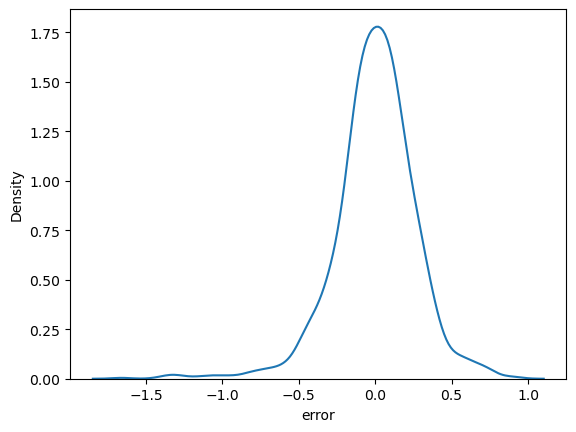

In [299]:
#Assumption 2
sns.kdeplot(x='error',data=df_model)

<Axes: xlabel='Calculated_SalePrice', ylabel='error'>

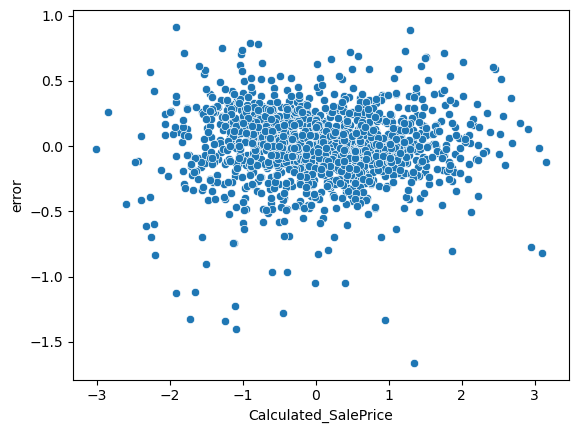

In [300]:
#Assumption 3
sns.scatterplot(x='Calculated_SalePrice',y='error',data=df_model)

Removed some outliers in the lower bound of sale price below -1.5 to increase R squared, change is visible in the SalePrice column. Error was correlated with Overall Quality and Neighborhood.